In [20]:
import os
import re
import subprocess
from concurrent.futures import ProcessPoolExecutor
from collections import defaultdict
import time

# --- HPC HARDWARE TUNING ---
TARGET_DIR = "/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT"
MAX_WORKERS = 32        # Leave 2 cores for system overhead
HADD_CORES_PER_TASK = 1 # 1 core per file is most efficient for mass-merging
COMPRESSION = 1         # 1 = Fast, 0 = Uncompressed (huge files but instant)

def get_file_groups(directory):
    groups = defaultdict(list)
    pattern = re.compile(r"(.+?)_{1,2}t\d+\.root")
    
    print(f"Scanning {directory}...")
    with os.scandir(directory) as it:
        for entry in it:
            if entry.is_file() and entry.name.endswith(".root"):
                match = pattern.match(entry.name)
                if match:
                    groups[os.path.join(directory, match.group(1))].append(entry.path)
    return groups

def fast_merge(base, parts):
    output_filename = f"{base}.root"
    
    # hadd -f1: sets compression to level 1 (very fast)
    # hadd -j 1: uses 1 core per command
    cmd = ["hadd", "-f1", "-j", str(HADD_CORES_PER_TASK), output_filename] + parts
    
    env = os.environ.copy()
    env["TMPDIR"] = TARGET_DIR # Keeps temp files off the slow system drive
    
    try:
        subprocess.run(cmd, capture_output=True, text=True, env=env, check=True)
        for p in parts:
            os.remove(p)
        return f"Done: {os.path.basename(output_filename)}"
    except Exception as e:
        return f"FAILED: {os.path.basename(output_filename)} | Error: {str(e)}"

if __name__ == "__main__":
    start_time = time.time()
    groups = get_file_groups(TARGET_DIR)
    total = len(groups)
    
    print(f"Scaling to {MAX_WORKERS} cores to merge {total} geometries...")

    with ProcessPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = [executor.submit(fast_merge, b, p) for b, p in groups.items()]
        
        for i, future in enumerate(futures):
            # Print progress every 10 files so the console isn't overwhelmed
            res = future.result()
            if (i + 1) % 10 == 0 or (i + 1) == total:
                print(f"[{i+1}/{total}] {res}")

    end_time = time.time()
    print(f"\nFinished in {(end_time - start_time)/60:.2f} minutes.")

Scanning /scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT...
Scaling to 32 cores to merge 128 geometries...
[10/128] Done: WLS_KR_Ref_Real_Hit6_Gap_0mm_Size_150mm_Thick_4mm_Tau_1.5ns.root
[20/128] Done: WLS_KR_Ref_Real_Hit6_Gap_0mm_Size_150mm_Thick_12mm_Tau_1.5ns.root
[30/128] Done: WLS_KR_Ref_Real_Hit6_Gap_0mm_Size_600mm_Thick_8mm_Tau_1.5ns.root
[40/128] Done: WLS_KR_Ref_Real_Hit6_Gap_0mm_Size_100mm_Thick_6mm_Tau_1.5ns.root
[50/128] Done: 8-inchPMT_Ref_Real_Det5.root
[60/128] Done: WLS_KR_Ref_Real_Hit6_Gap_0mm_Size_550mm_Thick_10mm_Tau_1.5ns.root
[70/128] Done: WLS_KR_Ref_Real_Hit6_Gap_0mm_Size_250mm_Thick_4mm_Tau_1.5ns.root
[80/128] Done: WLS_KR_Ref_Real_Hit6_Gap_0mm_Size_300mm_Thick_20mm_Tau_1.5ns.root
[90/128] Done: WLS_KR_Ref_Real_Hit6_Gap_0mm_Size_150mm_Thick_8mm_Tau_1.5ns.root
[100/128] Done: WLS_KR_Ref_Real_Hit6_Gap_0mm_Size_200mm_Thick_18mm_Tau_1.5ns.root
[110/128] Done: WLS_KR_Ref_Real_Hit6_Gap_0mm_Size_450mm_Thick_16mm_Tau_1.5ns.root
[120/128] Do

-------------------------------------------------------------------------------------
TOTAL PHOTON STATS (TIME < 50.0ns): COMPARISON TO 3-INCH BASELINE
-------------------------------------------------------------------------------------
Configuration        | Hits (Total) | Hit % Inc    | Dets (Total) | Det % Inc
---------------------+--------------+--------------+--------------+-----------
3-inch PMT           |       339545 | Baseline     |        53100 | Baseline
8-inch PMT           |      2494692 |      634.7% |       390312 |     635.1%
WLS Elbow            |       486961 |       43.4% |        73761 |      38.9%
-------------------------------------------------------------------------------------


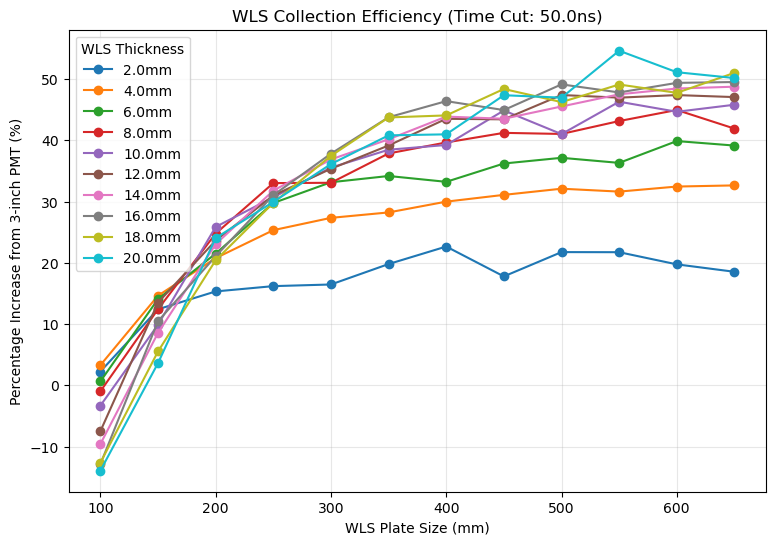

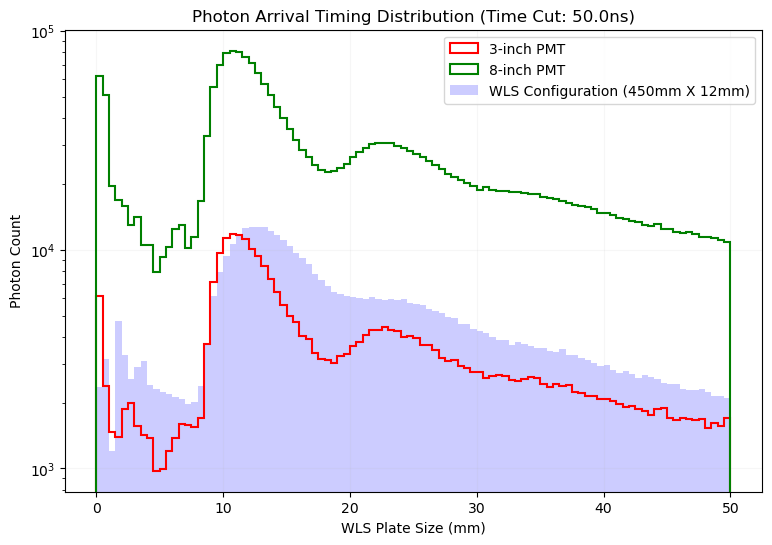

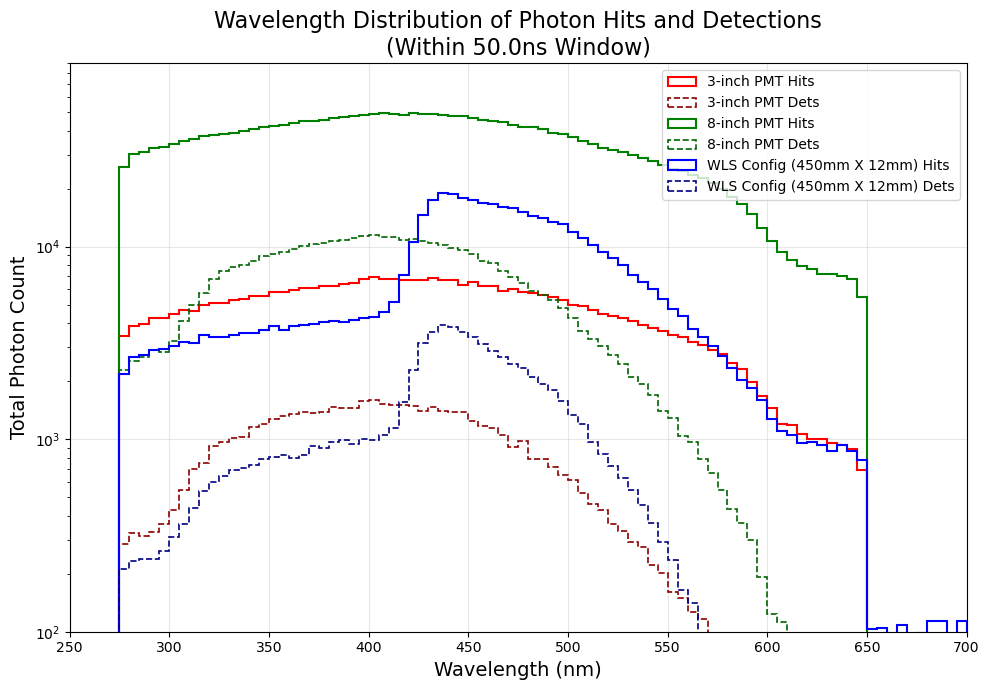

In [7]:
import uproot
import numpy as np
import matplotlib.pyplot as plt
import glob
import re

# --- CONFIGURATION ---
WLS_NAME, REF = "KR", "Real"
HIT_TYPES = ["Hit5", "Hit6"]  
DET_TYPES = ["Det5", "Det6"]  
NUM_EVENTS, TIME_CUT = 1000, 50.0  # Strict 50ns window applied throughout
ELBOW_SIZE, ELBOW_THICK = 450, 12
BASE_DIR = "/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT"

# Paper Formatting
LBL_FONT, TITLE_FONT, TIC_FONT, LEG_FONT = 14, 16, 12, 10
WAVE_BRANCH = "fwlen" 

# --- 1. LOAD BASELINES & COMBINED DATA (WITH 50ns CUT) ---
pmt_data_combined = {3: np.array([]), 8: np.array([])}
pmt_wl_hits = {3: np.array([]), 8: np.array([])}
pmt_wl_dets = {3: np.array([]), 8: np.array([])}
baseline_hits_per_file = {3: [], 8: []}

for pmt_size in [3, 8]:
    # 1a. Load Baseline HITS
    for h_type in HIT_TYPES:
        path = f"{BASE_DIR}/{pmt_size}-inchPMT_Ref_{REF}_{h_type}.root"
        try:
            with uproot.open(path) as f:
                tree = f["DetPhotons"]
                t = tree["fT"].array(library="np")
                mask = t < TIME_CUT
                filtered_t = t[mask]
                
                pmt_data_combined[pmt_size] = np.concatenate([pmt_data_combined[pmt_size], filtered_t])
                baseline_hits_per_file[pmt_size].append(len(filtered_t))
                
                if WAVE_BRANCH in tree.keys():
                    w = tree[WAVE_BRANCH].array(library="np")
                    pmt_wl_hits[pmt_size] = np.concatenate([pmt_wl_hits[pmt_size], w[mask]])
        except Exception as e: print(f"Warning: Missing {h_type} baseline {path}")

    # 1b. Load Baseline DETS (Applying 50ns Cut)
    for d_type in DET_TYPES:
        path = f"{BASE_DIR}/{pmt_size}-inchPMT_Ref_{REF}_{d_type}.root"
        try:
            with uproot.open(path) as f:
                tree = f["DetPhotons"]
                t = tree["fT"].array(library="np")
                mask = t < TIME_CUT
                if WAVE_BRANCH in tree.keys():
                    w = tree[WAVE_BRANCH].array(library="np")
                    pmt_wl_dets[pmt_size] = np.concatenate([pmt_wl_dets[pmt_size], w[mask]])
        except: pass

# Baseline mean for % Increase logic
avg_baseline_3in = np.mean(baseline_hits_per_file[3]) / NUM_EVENTS if baseline_hits_per_file[3] else 1

# --- 2. PROCESS WLS FILES (WITH 50ns CUT) ---
raw_wls_hits = {} 
elbow_timing_combined = np.array([]) 
elbow_wl_hits = np.array([]) 
elbow_wl_dets = np.array([]) 
size_timing_data = {} 

# 2a. Process WLS HITS
for h_type in HIT_TYPES:
    wls_files = glob.glob(f"{BASE_DIR}/WLS_{WLS_NAME}_Ref_{REF}_{h_type}_Gap_0mm_Size_*mm_Thick_*mm_Tau_1.5ns.root")
    for fpath in wls_files:
        match = re.search(r"Size_(\d+\.?\d*)mm_Thick_(\d+\.?\d*)mm", fpath)
        if not match: continue
        size, thick = float(match.group(1)), float(match.group(2))
        key = (size, thick)
        try:
            with uproot.open(fpath) as f:
                tree = f["DetPhotons"]
                t = tree["fT"].array(library="np")
                mask = t < TIME_CUT
                hits_in_window = t[mask]
                
                if key not in raw_wls_hits: raw_wls_hits[key] = []
                raw_wls_hits[key].append(len(hits_in_window) / NUM_EVENTS)
                
                if abs(thick - ELBOW_THICK) < 0.1:
                    if size not in size_timing_data: size_timing_data[size] = np.array([])
                    size_timing_data[size] = np.concatenate([size_timing_data[size], hits_in_window])
                
                if abs(size - ELBOW_SIZE) < 0.1 and abs(thick - ELBOW_THICK) < 0.1:
                    elbow_timing_combined = np.concatenate([elbow_timing_combined, hits_in_window])
                    if WAVE_BRANCH in tree.keys():
                        w = tree[WAVE_BRANCH].array(library="np")
                        elbow_wl_hits = np.concatenate([elbow_wl_hits, w[mask]])
        except: pass

# 2b. Process WLS DETS (Applying 50ns Cut to Elbow Config)
for d_type in DET_TYPES:
    fpath = f"{BASE_DIR}/WLS_{WLS_NAME}_Ref_{REF}_{d_type}_Gap_0mm_Size_{ELBOW_SIZE}mm_Thick_{ELBOW_THICK}mm_Tau_1.5ns.root"
    try:
        with uproot.open(fpath) as f:
            tree = f["DetPhotons"]
            t = tree["fT"].array(library="np")
            mask = t < TIME_CUT
            if WAVE_BRANCH in tree.keys():
                w = tree[WAVE_BRANCH].array(library="np")
                elbow_wl_dets = np.concatenate([elbow_wl_dets, w[mask]])
    except: pass

# --- 3. TERMINAL STATS (TOTAL PHOTONS WITHIN 50ns & % INC) ---
total_hits_3in = len(pmt_wl_hits[3])
total_dets_3in = len(pmt_wl_dets[3])

def get_inc(current, baseline):
    return ((current / baseline) - 1) * 100 if baseline > 0 else 0

print("-" * 85)
print(f"TOTAL PHOTON STATS (TIME < {TIME_CUT}ns): COMPARISON TO 3-INCH BASELINE")
print("-" * 85)
print(f"{'Configuration':<20} | {'Hits (Total)':<12} | {'Hit % Inc':<12} | {'Dets (Total)':<12} | {'Det % Inc'}")
print(f"{'-'*20}-+-{'-'*12}-+-{'-'*12}-+-{'-'*12}-+-{'-'*10}")
print(f"{'3-inch PMT':<20} | {total_hits_3in:>12} | {'Baseline':<12} | {total_dets_3in:>12} | {'Baseline'}")
print(f"{'8-inch PMT':<20} | {len(pmt_wl_hits[8]):>12} | {get_inc(len(pmt_wl_hits[8]), total_hits_3in):>10.1f}% | {len(pmt_wl_dets[8]):>12} | {get_inc(len(pmt_wl_dets[8]), total_dets_3in):>9.1f}%")
print(f"{'WLS Elbow':<20} | {len(elbow_wl_hits):>12} | {get_inc(len(elbow_wl_hits), total_hits_3in):>10.1f}% | {len(elbow_wl_dets):>12} | {get_inc(len(elbow_wl_dets), total_dets_3in):>9.1f}%")
print("-" * 85)

# --- 4. PLOTS ---

# Plot 1: Efficiency Increase (Hits)
plt.figure(figsize=(9, 6))
efficiency_results = {} 
for (size, thick), hits_list in raw_wls_hits.items():
    if len(hits_list) > 0:
        mean_hits = np.mean(hits_list)
        pct_inc = ((mean_hits / avg_baseline_3in) - 1) * 100
        if thick not in efficiency_results: efficiency_results[thick] = {"s": [], "p": []}
        efficiency_results[thick]["s"].append(size); efficiency_results[thick]["p"].append(pct_inc)

for thick in sorted(efficiency_results.keys()):
    res = efficiency_results[thick]
    idx = np.argsort(res["s"])
    plt.plot(np.array(res["s"])[idx], np.array(res["p"])[idx], 'o-', label=f"{thick}mm")
plt.title(f"WLS Collection Efficiency (Time Cut: {TIME_CUT}ns)"); plt.ylabel("Percentage Increase from 3-inch PMT (%)");plt.xlabel("WLS Plate Size (mm)"); plt.legend(title="WLS Thickness", loc = 'upper left'); plt.grid(True, alpha=0.3)

# Plot 2: Total Timing
plt.figure(figsize=(9, 6))
bins = np.linspace(0, TIME_CUT, 101)
plt.hist(pmt_data_combined[3], bins=bins, histtype='step', color='red', label='3-inch PMT', linewidth=1.5)
plt.hist(pmt_data_combined[8], bins=bins, histtype='step', color='green', label='8-inch PMT', linewidth=1.5)
plt.hist(elbow_timing_combined, bins=bins, histtype='stepfilled', color='blue', alpha=0.2, label='WLS Configuration (450mm X 12mm)')
plt.yscale('log'); plt.title(f"Photon Arrival Timing Distribution (Time Cut: {TIME_CUT}ns)"); plt.ylabel("Photon Count");plt.xlabel("WLS Plate Size (mm)"); plt.legend(); plt.grid(True, alpha=0.1)

# Plot 3: Total Wavelength Distribution (Hits vs Detections)
plt.figure(figsize=(10, 7))
wl_bins = np.linspace(200, 700, 101) 

def plot_total_wave(hits, dets, label, c_h, c_d):
    if len(hits) > 0:
        plt.hist(hits, bins=wl_bins, histtype='step', color=c_h, label=f'{label} Hits', linewidth=1.5)
    if len(dets) > 0:
        plt.hist(dets, bins=wl_bins, histtype='step', color=c_d, linestyle='--', label=f'{label} Dets', linewidth=1.2)

plot_total_wave(pmt_wl_hits[3], pmt_wl_dets[3], '3-inch PMT', 'red', 'darkred')
plot_total_wave(pmt_wl_hits[8], pmt_wl_dets[8], '8-inch PMT', 'green', 'darkgreen')
plot_total_wave(elbow_wl_hits, elbow_wl_dets, 'WLS Config (450mm X 12mm)', 'blue', 'navy')

plt.title(f"Wavelength Distribution of Photon Hits and Detections\n(Within {TIME_CUT}ns Window)", fontsize=TITLE_FONT)
plt.xlabel("Wavelength (nm)", fontsize=LBL_FONT); plt.ylabel("Total Photon Count", fontsize=LBL_FONT)
plt.legend(); plt.grid(True, alpha=0.3)
plt.yscale('log');
plt.ylim(1e2,9e4); plt.xlim(250,700)
plt.tight_layout(); plt.show()


--- AUDITING SIZE VARIATION (Averaging Hit5 & Hit6) ---
Value  | Hits %   | Esc %    | Self %   | Mirr %   | Diff
---------------------------------------------------------------------------


100mm   |  39.98% |  36.62% |  17.57% |   5.83% | 0
150mm   |  22.57% |  43.23% |  27.16% |   7.04% | 0
200mm   |  14.57% |  45.43% |  32.46% |   7.53% | 0
250mm   |   9.97% |  46.45% |  35.92% |   7.66% | 0
300mm   |   7.31% |  46.85% |  38.13% |   7.71% | 0
350mm   |   5.50% |  47.19% |  39.60% |   7.70% | 0
400mm   |   4.28% |  47.32% |  40.73% |   7.67% | 0
450mm   |   3.44% |  47.38% |  41.53% |   7.65% | 0
500mm   |   2.80% |  47.39% |  42.17% |   7.63% | 0
550mm   |   2.33% |  47.38% |  42.66% |   7.63% | 0
600mm   |   1.99% |  47.35% |  43.08% |   7.58% | 0
650mm   |   1.72% |  47.27% |  43.42% |   7.59% | 0

--- AUDITING THICK VARIATION (Averaging Hit5 & Hit6) ---
Value  | Hits %   | Esc %    | Self %   | Mirr %   | Diff
---------------------------------------------------------------------------
  2mm   |   2.48% |  51.63% |  27.43% |  18.46% | 0
  4mm   |   2.93% |  50.52% |  33.28% |  13.27% | 0
  6mm   |   3.15% |  49.62% |  36.44% |  10.79% | 0
  8mm   |   3.28% |  48.82% 

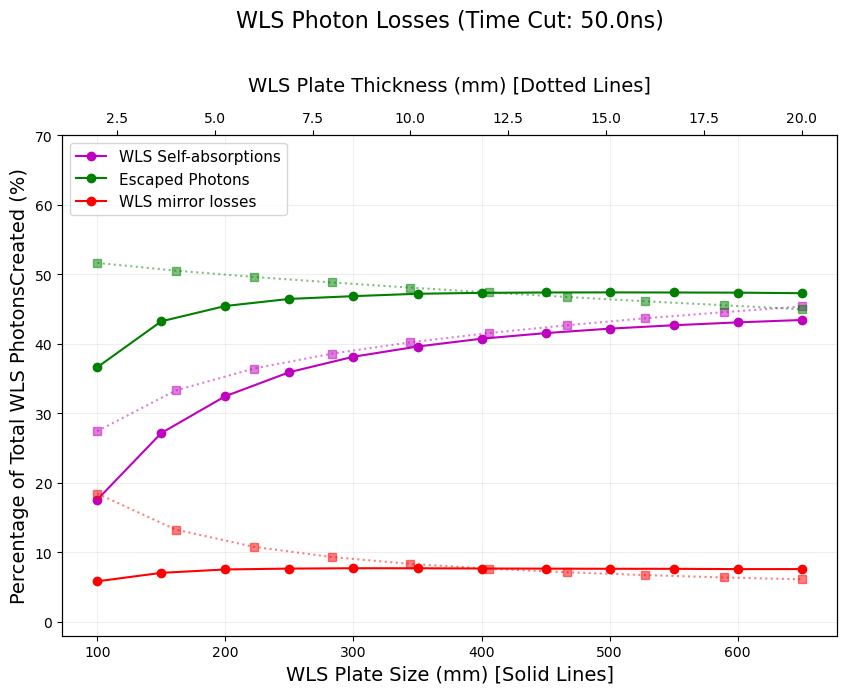

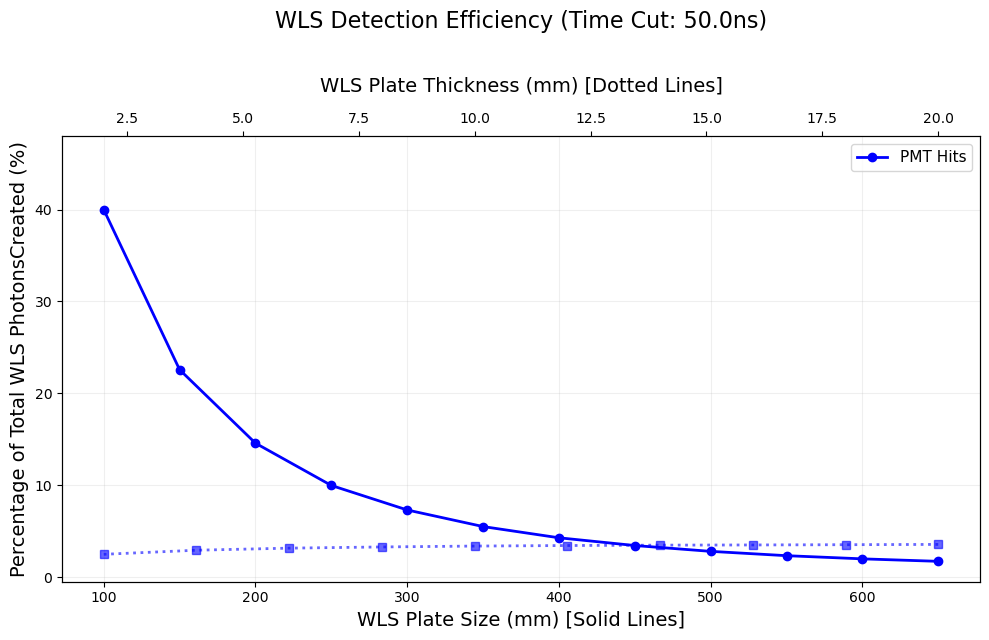

In [7]:
import uproot
import glob
import re
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION ---
BASE_DIR = "/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT"
TYPES = ["Hit5", "Hit6"]
WLS_NAME, REF = "KR", "Real"

# --- 2. FILE DISCOVERY (Using the robust timing-script logic) ---
def get_grouped_files(target_var, fixed_val, fixed_name):
    """Groups Hit5 and Hit6 files using regex filtering."""
    groups = defaultdict(list)
    
    for h_type in TYPES:
        # Using the broader glob that worked in the timing script
        pattern = f"{BASE_DIR}/WLS_{WLS_NAME}_Ref_{REF}_{h_type}_Gap_0mm_Size_*mm_Thick_*mm_Tau_1.5ns.root"
        all_files = glob.glob(pattern)
        
        for f in all_files:
            # Extract size and thickness from filename
            match = re.search(r"Size_(\d+\.?\d*)mm_Thick_(\d+\.?\d*)mm", f)
            if not match: continue
            
            size, thick = float(match.group(1)), float(match.group(2))
            
            # Filter for the fixed dimension (e.g., if Size sweep, check if Thick == 12)
            current_val = size if target_var == "Size" else thick
            comparison_val = thick if target_var == "Size" else size
            
            if abs(comparison_val - fixed_val) < 0.1:
                groups[int(current_val)].append(f)
                
    return groups

# Initialize groups
size_groups = get_grouped_files("Size", 12, "Thick")
thick_groups = get_grouped_files("Thick", 450, "Size")

# --- 3. PROCESSING FUNCTION ---
def process_and_audit_averaged(grouped_files, var_type="Size"):
    results = {"var": [], "hits_p": [], "self_p": [], "mirrors_p": [], "escapes_p": []}
    
    if not grouped_files:
        print(f"Warning: No files found for {var_type} sweep.")
        return results

    print(f"\n--- AUDITING {var_type.upper()} VARIATION (Averaging Hit5 & Hit6) ---")
    print(f"{'Value':<6} | {'Hits %':<8} | {'Esc %':<8} | {'Self %':<8} | {'Mirr %':<8} | {'Diff'}")
    print("-" * 75)
    
    for val in sorted(grouped_files.keys()):
        file_list = grouped_files[val]
        
        # Aggregate raw counts across all files in the group (Hit5 + Hit6)
        total_n4, total_hits, total_self, total_mirrors, total_escapes, total_int = 0, 0, 0, 0, 0, 0
        
        for f_path in file_list:
            with uproot.open(f_path) as f:
                n4_total = f["EmmPhotons"].num_entries
                total_n4 += n4_total
                
                # PMT Hits
                n0 = f["DetPhotons"].arrays(["fEvent", "fTrackEvent"], library="np")
                det_ids = set(zip(n0["fEvent"], n0["fTrackEvent"]))
                
                # Process Fates
                d = f["WLSPhotons"].arrays(["fProcessName", "fPreVolumeID", "fPostVolumeID", "fEvent", "fTrackEvent"], library="np")
                counts = Counter(zip(d["fProcessName"], d["fPreVolumeID"], d["fPostVolumeID"]))
                
                for (proc, pre, post), count in counts.items():
                    if proc == "OpWLS":
                        total_self += count
                        continue
                    
                    mask = (d["fProcessName"] == proc) & (d["fPreVolumeID"] == pre) & (d["fPostVolumeID"] == post)
                    path_ids = zip(d["fEvent"][mask], d["fTrackEvent"][mask])
                    h_count = sum(1 for pid in path_ids if pid in det_ids)
                    
                    total_hits += h_count
                    rem = count - h_count
                    if rem <= 0: continue
                    
                    if (101 <= post <= 115) or (101 <= pre <= 115): 
                        total_mirrors += rem
                    elif pre in [7, 8] or post in [7, 8]: 
                        total_escapes += rem
                    else: 
                        total_int += rem

        # Stats
        h_p, e_p, s_p, m_p = (total_hits/total_n4)*100, (total_escapes/total_n4)*100, (total_self/total_n4)*100, (total_mirrors/total_n4)*100
        diff = total_n4 - (total_self + total_hits + total_mirrors + total_escapes + total_int)
        
        results["var"].append(val)
        results["hits_p"].append(h_p); results["self_p"].append(s_p)
        results["mirrors_p"].append(m_p); results["escapes_p"].append(e_p)
        
        print(f"{val:>3}mm   | {h_p:>6.2f}% | {e_p:>6.2f}% | {s_p:>6.2f}% | {m_p:>6.2f}% | {diff}")
            
    return results

size_res = process_and_audit_averaged(size_groups, "Size")
thick_res = process_and_audit_averaged(thick_groups, "Thick")

# --- 4. PLOTTING ---
LBL_FONT, TITLE_FONT, TIC_FONT, LEG_FONT = 14, 16, 12, 11

if size_res["var"] and thick_res["var"]:
    # Plot 1: Losses
    fig1, ax1_bot = plt.subplots(figsize=(10, 6.5))
    ax1_top = ax1_bot.twiny()
    
    ax1_bot.plot(size_res["var"], size_res["self_p"], 'm-o', label='WLS Self-absorptions')
    ax1_bot.plot(size_res["var"], size_res["escapes_p"], 'g-o', label='Escaped Photons')
    ax1_bot.plot(size_res["var"], size_res["mirrors_p"], 'r-o', label='WLS mirror losses')
    
    ax1_top.plot(thick_res["var"], thick_res["self_p"], 'm:s', alpha=0.5)
    ax1_top.plot(thick_res["var"], thick_res["escapes_p"], 'g:s', alpha=0.5)
    ax1_top.plot(thick_res["var"], thick_res["mirrors_p"], 'r:s', alpha=0.5)
    
    ax1_bot.set_ylabel('Percentage of Total WLS PhotonsCreated (%)', fontsize=LBL_FONT)
    ax1_bot.set_xlabel('WLS Plate Size (mm) [Solid Lines]', fontsize=LBL_FONT)
    
    # ADDED LABELPAD AND PAD
    ax1_top.set_xlabel('WLS Plate Thickness (mm) [Dotted Lines]', fontsize=LBL_FONT, labelpad=15)
    ax1_bot.set_title(f"WLS Photon Losses (Time Cut: {TIME_CUT}ns)", fontsize=TITLE_FONT, pad=35)
    
    ax1_bot.set_ylim(-2, 70)
    ax1_bot.legend(loc='upper left', fontsize=LEG_FONT)
    ax1_bot.grid(True, alpha=0.2)

    # Plot 2: Hits
    fig2, ax2_bot = plt.subplots(figsize=(10, 6.5))
    ax2_top = ax2_bot.twiny()
    
    ax2_bot.plot(size_res["var"], size_res["hits_p"], 'b-o', lw=2, label='PMT Hits')
    ax2_top.plot(thick_res["var"], thick_res["hits_p"], 'b:s', lw=2, alpha=0.6)
    
    ax2_bot.set_ylabel('Percentage of Total WLS PhotonsCreated (%)', fontsize=LBL_FONT)
    ax2_bot.set_xlabel('WLS Plate Size (mm) [Solid Lines]', fontsize=LBL_FONT)
    
    # ADDED LABELPAD AND PAD
    ax2_top.set_xlabel('WLS Plate Thickness (mm) [Dotted Lines]', fontsize=LBL_FONT, labelpad=15)
    ax2_bot.set_title(f"WLS Detection Efficiency (Time Cut: {TIME_CUT}ns)", fontsize=TITLE_FONT, pad=35)
    
    all_hits = size_res["hits_p"] + thick_res["hits_p"]
    ax2_bot.set_ylim(-0.5, max(all_hits) * 1.2)
    ax2_bot.legend(loc='upper right', fontsize=LEG_FONT)
    ax2_bot.grid(True, alpha=0.2)
    
    plt.tight_layout() # Ensures everything fits within the figure bounds
    plt.show()

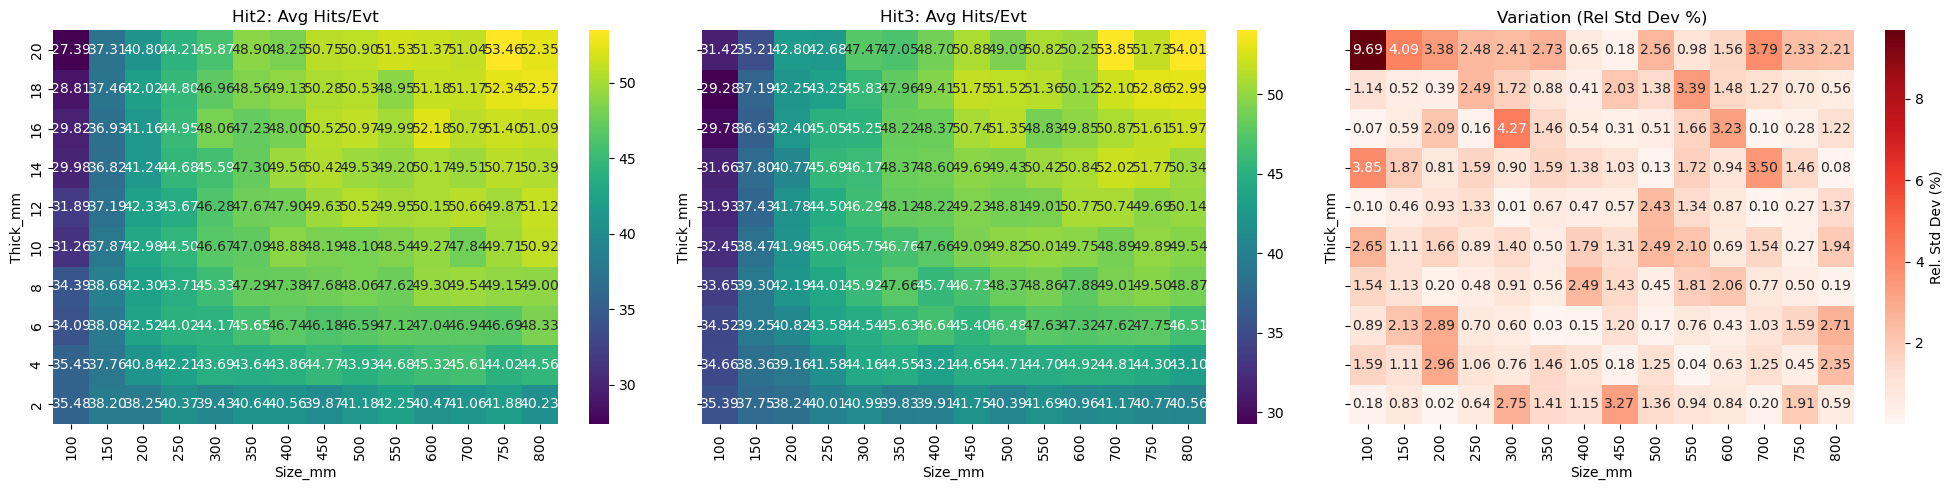

In [3]:
import uproot
import glob
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION ---
N_EVENTS = 5000
CUT_TIME = 50.0
WLS = "KR"
REF = "Real"
TAU = "1.5"

def get_seed_data(hit_type):
    file_pattern = f"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_{WLS}_Ref_{REF}_{hit_type}_Gap_0mm_Size_*mm_Thick_*mm_Tau_{TAU}ns.root"
    regex_parser = re.compile(fr"_{hit_type}_Gap_0mm_Size_(\d+)mm_Thick_(\d+)mm")
    files = glob.glob(file_pattern)
    results = {}
    for f in files:
        match = regex_parser.search(f)
        if not match: continue
        size, thick = int(match.group(1)), int(match.group(2))
        try:
            with uproot.open(f) as root_f:
                t_obj = root_f["DetPhotons"] if "DetPhotons" in root_f else next(iter(root_f.values()))
                times = t_obj.arrays("fT", library="np")["fT"]
                results[(size, thick)] = np.sum(times < CUT_TIME) / N_EVENTS
        except Exception: continue
    return results

# --- 2. DATA PROCESSING ---
data_h2 = get_seed_data("Hit2")
data_h3 = get_seed_data("Hit3")
common_configs = sorted(set(data_h2.keys()).intersection(set(data_h3.keys())))

stats_list = []
for config in common_configs:
    val2, val3 = data_h2[config], data_h3[config]
    std_dev = np.std([val2, val3], ddof=1)
    mean_val = (val2 + val3) / 2
    rel_std_dev = (std_dev / mean_val * 100) if mean_val > 0 else 0
    stats_list.append({
        "Size_mm": config[0], "Thick_mm": config[1],
        "Hit2_Rate": val2, "Hit3_Rate": val3,
        "Mean_Rate": mean_val, "Rel_Std_Dev_%": rel_std_dev
    })

df = pd.DataFrame(stats_list)

# --- 3. PLOTTING ---
pivot_h2 = df.pivot(index="Thick_mm", columns="Size_mm", values="Hit2_Rate")
pivot_h3 = df.pivot(index="Thick_mm", columns="Size_mm", values="Hit3_Rate")
pivot_var = df.pivot(index="Thick_mm", columns="Size_mm", values="Rel_Std_Dev_%")

fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
sns.heatmap(pivot_h2, annot=True, fmt=".2f", cmap="viridis", ax=axes[0])
axes[0].set_title("Hit2: Avg Hits/Evt")
axes[0].invert_yaxis()

sns.heatmap(pivot_h3, annot=True, fmt=".2f", cmap="viridis", ax=axes[1])
axes[1].set_title("Hit3: Avg Hits/Evt")
axes[1].invert_yaxis()

sns.heatmap(pivot_var, annot=True, fmt=".2f", cmap="Reds", ax=axes[2], cbar_kws={'label': 'Rel. Std Dev (%)'})
axes[2].set_title("Variation (Rel Std Dev %)")
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

--- COMPARING RAW COUNTS AT 10mm THICKNESS ---
  -> Batch 1 PMT Baseline: 125112 hits (mapped to 1.0x)
Loading 11 WLS files for Batch 1 (Polished WLS-PMT Boundary: Gap = 0mm, Shell PMT, 100 Ref)...
  -> Batch 2 PMT Baseline: 235278 hits (mapped to 1.0x)
  [Warning] No WLS files found for Batch 2 (Polished WLS-PMT Boundary: Gap = 0mm, Shell PMT, Real Ref) at /scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/


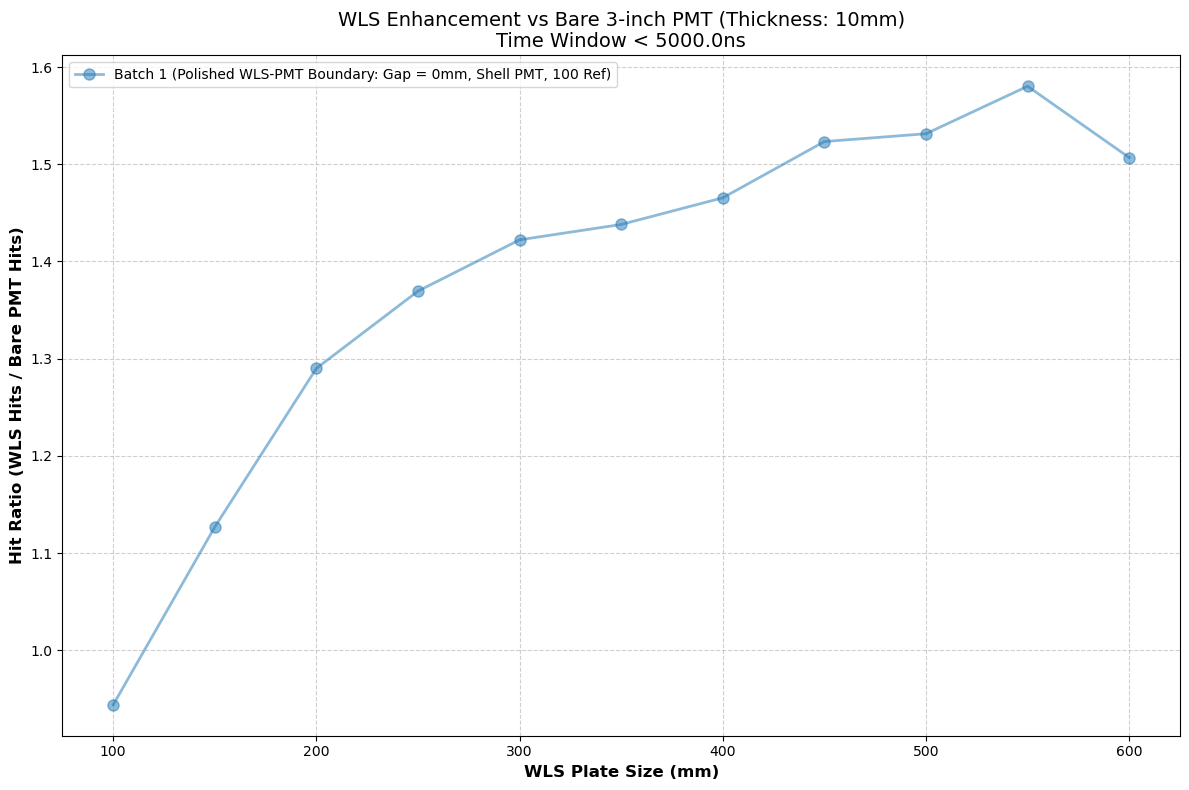

In [4]:
import uproot
import glob
import re
import matplotlib.pyplot as plt
import numpy as np
import itertools # Added to handle infinite color/marker cycling

# --- CONFIGURATION ---
DATASETS = {
    "Batch 1 (Polished WLS-PMT Boundary: Gap = 0mm, Shell PMT, 100 Ref)":  {"dir": "/scratch/alice/j/jss55/G4Data/NewMuonGen_100Ref_PolishedWLSPMTBound_ShellPMT/",  "type": "Hit", "gap": "_Gap_0mm", "ref": "100"},
    "Batch 2 (Polished WLS-PMT Boundary: Gap = 0mm, Shell PMT, Real Ref)": {"dir": "/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/", "type": "Hit", "gap": "_Gap_0mm", "ref": "Real"},
}

TARGET_THICKNESS = 10   # mm
CUT_TIME = 5000.0         # Set to 10.0 if you only want early hits, 5000.0 for total raw hits
WLS = "KR"
TAU = "1.5"

print(f"--- COMPARING RAW COUNTS AT {TARGET_THICKNESS}mm THICKNESS ---")

# Setup Plot
plt.figure(figsize=(12, 8))

# DYNAMIC STYLING SETUP
# Grab Matplotlib's default 10-color palette and make it loop indefinitely
color_cycle = itertools.cycle(plt.rcParams['axes.prop_cycle'].by_key()['color'])
# Make a list of distinct markers and make it loop indefinitely
marker_cycle = itertools.cycle(['o', 's', '^', 'D', 'v', 'p', '*', 'h', 'X'])

# Loop through each directory using the dynamic cycles
for (label, info), color, marker in zip(DATASETS.items(), color_cycle, marker_cycle):
    directory = info["dir"]
    batch_type = info["type"]
    gap_str = info["gap"]
    ref_val = info["ref"]
    
    # 1. --- PROCESS 3-INCH PMT BASELINE FIRST ---
    pmt_pattern = f"{directory}3-inchPMT_Ref_{ref_val}_{batch_type}*.root"
    pmt_files = glob.glob(pmt_pattern)
    pmt_hits = None
    
    if pmt_files:
        pmt_file = pmt_files[0] 
        try:
            with uproot.open(pmt_file) as p_f:
                p_obj = p_f["DetPhotons"] if "DetPhotons" in p_f else next(iter(p_f.values()))
                if p_obj.num_entries == 0:
                    pmt_hits = 0
                else:
                    p_times = p_obj["fT"].array(library="np")
                    pmt_hits = np.sum(p_times < CUT_TIME)
        except Exception as e:
            print(f"  [Error] Failed to read PMT file {pmt_file}: {e}")
    else:
        print(f"  [Notice] No 3-inch PMT reference file found matching {pmt_pattern}")

    if pmt_hits is None or pmt_hits == 0:
        print(f"  [Warning] Cannot calculate fraction for {label} because PMT baseline hits = 0 or missing.")
        continue
    else:
        short_label = label.split('(')[0].strip() 
        print(f"  -> {short_label} PMT Baseline: {pmt_hits} hits (mapped to 1.0x)")

    # 2. --- PROCESS WLS DATA ---
    regex_parser = re.compile(fr"_{batch_type}{gap_str}_Size_(\d+)mm_Thick_{TARGET_THICKNESS}mm")
    file_pattern = f"{directory}WLS_{WLS}_Ref_{ref_val}_{batch_type}{gap_str}_Size_*mm_Thick_{TARGET_THICKNESS}mm_Tau_{TAU}ns.root"
    files = glob.glob(file_pattern)
    
    sizes = []
    fractions = []
    
    if not files:
        print(f"  [Warning] No WLS files found for {label} at {directory}")
    else:
        print(f"Loading {len(files)} WLS files for {label}...")
        for f in files:
            match = regex_parser.search(f)
            if not match: continue
            
            size_val = int(match.group(1))
            
            try:
                with uproot.open(f) as root_f:
                    t_obj = root_f["DetPhotons"] if "DetPhotons" in root_f else next(iter(root_f.values()))
                    
                    if t_obj.num_entries == 0:
                        hits = 0
                    else:
                        times = t_obj["fT"].array(library="np")
                        hits = np.sum(times < CUT_TIME)
                    
                    sizes.append(size_val)
                    fractions.append(hits / pmt_hits)
                    
            except Exception as e:
                print(f"  [Error] Failed to read {f}: {e}")
                
        # Plot the WLS line
        if sizes:
            sorted_indices = np.argsort(sizes)
            sizes_sorted = np.array(sizes)[sorted_indices]
            fractions_sorted = np.array(fractions)[sorted_indices]
            
            plt.plot(sizes_sorted, fractions_sorted, marker=marker, color=color, 
                     linewidth=2, markersize=8, alpha=0.5, label=label)

# --- FORMAT PLOT ---
plt.title(f"WLS Enhancement vs Bare 3-inch PMT (Thickness: {TARGET_THICKNESS}mm)\nTime Window < {CUT_TIME}ns", fontsize=14)
plt.xlabel("WLS Plate Size (mm)", fontsize=12, fontweight='bold')
plt.ylabel("Hit Ratio (WLS Hits / Bare PMT Hits)", fontsize=12, fontweight='bold')

plt.legend(loc="best")
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

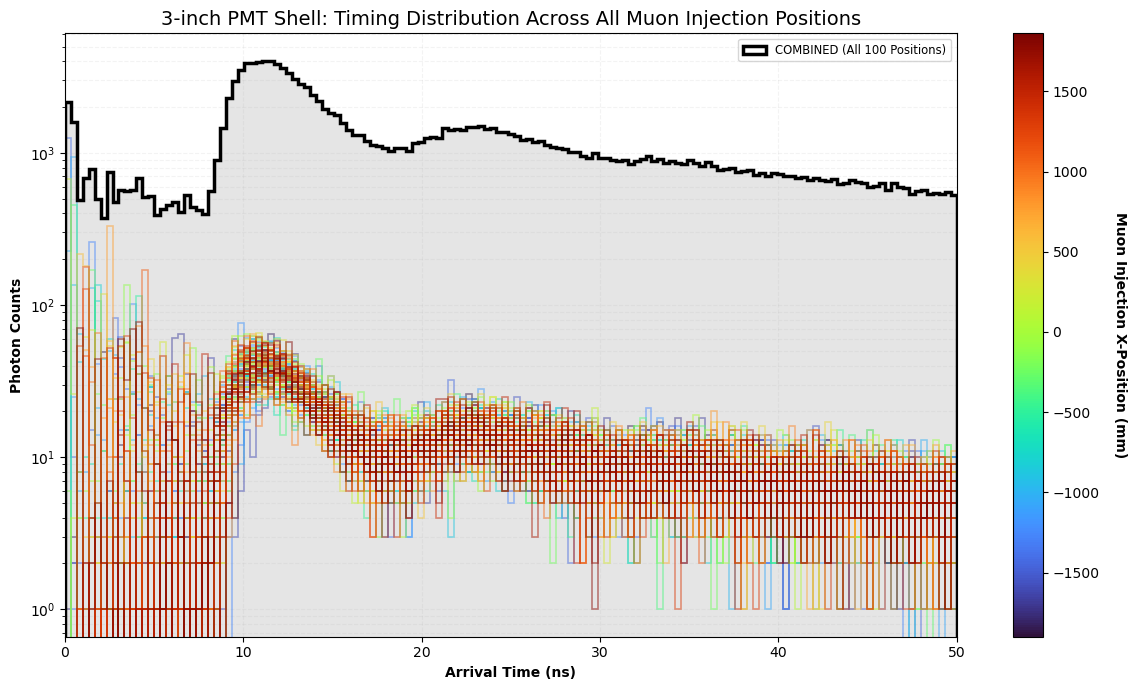

In [5]:
import uproot
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# --- CONFIGURATION ---
FILE_PATH = "/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/3-inchPMT_Ref_Real_Hit1.root"
STEPS_PER_PASS = 100
TIME_WINDOW = 50.0  

def plot_muon_sweep_all_positions(file_path):
    try:
        with uproot.open(file_path) as f:
            # Dynamically get tree name
            tree_name = "DetPhotons" if "DetPhotons" in f else next(iter(f.keys()))
            tree = f[tree_name]
            
            # Load Data
            data = tree.arrays(["fT", "fEvent"], library="np")
            times = data["fT"]
            event_ids = data["fEvent"]

            plt.figure(figsize=(12, 7))
            bins = np.linspace(0, TIME_WINDOW, 150)
            
            # --- COLORMAP SETUP ---
            # 'turbo', 'viridis', or 'plasma' work well for sweeps. 
            cmap = plt.get_cmap('turbo') 
            
            # Normalize colors across the X-positions (-1900mm to +1862mm)
            min_x = -1900
            max_x = -1900 + ((STEPS_PER_PASS - 1) * 38)
            norm = mcolors.Normalize(vmin=min_x, vmax=max_x)

            # --- 1. PLOT EVERY POSITION ---
            # Loop through all 100 positions
            for idx in range(STEPS_PER_PASS):
                mask = (event_ids % STEPS_PER_PASS) == idx
                pos_times = times[mask]
                
                if len(pos_times) > 0:
                    # Calculate physical X-position in mm to assign the correct color
                    x_pos_mm = -1900 + (idx * 38)
                    color = cmap(norm(x_pos_mm))
                    
                    # Alpha is set to 0.5 so overlapping lines blend nicely
                    plt.hist(pos_times, bins=bins, histtype='step', 
                             color=color, linewidth=1.2, alpha=0.5)

            # --- 2. PLOT TRUE COMBINED DISTRIBUTION (Black Outline) ---
            if len(times) > 0:
                plt.hist(times, bins=bins, histtype='step', 
                         color='black', linewidth=2.5, zorder=10,
                         label=f"COMBINED (All {STEPS_PER_PASS} Positions)")
                
                # Light grey fill for the true combined distribution
                plt.hist(times, bins=bins, histtype='stepfilled', 
                         color='black', alpha=0.1, zorder=1)

            # --- AESTHETICS ---
            plt.title("3-inch PMT Shell: Timing Distribution Across All Muon Injection Positions", fontsize=14)
            plt.xlabel("Arrival Time (ns)", fontweight='bold')
            plt.ylabel("Photon Counts", fontweight='bold')
            
            plt.yscale('log')
            plt.xlim(0, TIME_WINDOW)
            plt.grid(True, which="both", alpha=0.15, linestyle='--')
            
            # --- COLORBAR (Replaces the massive legend) ---
            sm = cm.ScalarMappable(cmap=cmap, norm=norm)
            sm.set_array([])
            cbar = plt.colorbar(sm, ax=plt.gca())
            cbar.set_label('Muon Injection X-Position (mm)', fontweight='bold', rotation=270, labelpad=20)
            
            plt.legend(loc='upper right', fontsize='small')
            
            plt.tight_layout()
            plt.show()

    except Exception as e:
        print(f"Error processing file: {e}")

# Run the plot
plot_muon_sweep_all_positions(FILE_PATH)

Successfully loaded 125118 photons from 3-inch Solid PMT
Successfully loaded 125112 photons from 3-inch Shell PMT
Generating Timing Resolution Histogram...


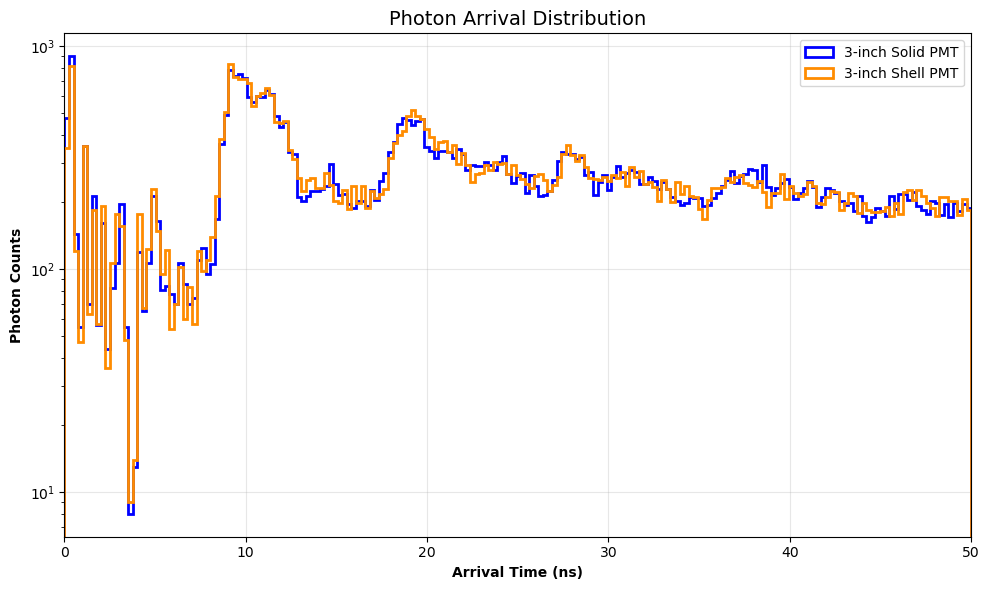

In [6]:
import uproot
import matplotlib.pyplot as plt
import numpy as np

# --- CONFIGURATION ---
# The two specific files you want to compare
files_to_compare = {
    "3-inch Solid PMT": "/scratch/alice/j/jss55/G4Data/NewMuonGen_100Ref_PolishedWLSPMTBound_SolidPMT/3-inchPMT_Ref_100_Hit.root",
    "3-inch Shell PMT": "/scratch/alice/j/jss55/G4Data/NewMuonGen_100Ref_PolishedWLSPMTBound_ShellPMT/3-inchPMT_Ref_100_Hit.root"
}

# Plot styling
colors = {"3-inch Solid PMT": "blue", "3-inch Shell PMT": "darkorange"}

# --- DATA ACQUISITION ---
loaded_data = {}

for label, filepath in files_to_compare.items():
    try:
        with uproot.open(filepath) as f:
            # Find the correct tree
            t_obj = f["DetPhotons"] if "DetPhotons" in f else next(iter(f.values()))
            
            # Extract just the timing array
            times = t_obj.arrays(["fT"], library="np")["fT"]
            loaded_data[label] = times
            print(f"Successfully loaded {len(times)} photons from {label}")
            
    except Exception as e:
        print(f"Error loading {filepath}: {e}")

# --- PLOTTING: TIMING RESOLUTION HISTOGRAM ---
print("Generating Timing Resolution Histogram...")

fig, ax = plt.subplots(figsize=(10, 6))

# Define Histogram Bins (0 to 20ns, 0.2ns width)
bins = np.linspace(0, 50, 200) 

for label, times in loaded_data.items():
    # Filter for a reasonable window to avoid extreme outliers messing up the plot
    valid_times = times[(times > 0) & (times < 50)]
    
    if len(valid_times) > 0:
        # Plot as a step histogram (raw counts, log scale)
        ax.hist(valid_times, bins=bins, density=False, histtype='step', 
                linewidth=2, color=colors[label], label=label)

# Formatting
ax.set_xlabel("Arrival Time (ns)", fontweight='bold')
ax.set_ylabel("Photon Counts", fontweight='bold')
ax.set_title("Photon Arrival Distribution", fontsize=14)
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 50)
ax.set_yscale('log')

plt.tight_layout()
plt.show()

/local/jss55/ipykernel_1838312/257362523.py:99: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='best', frameon=True)


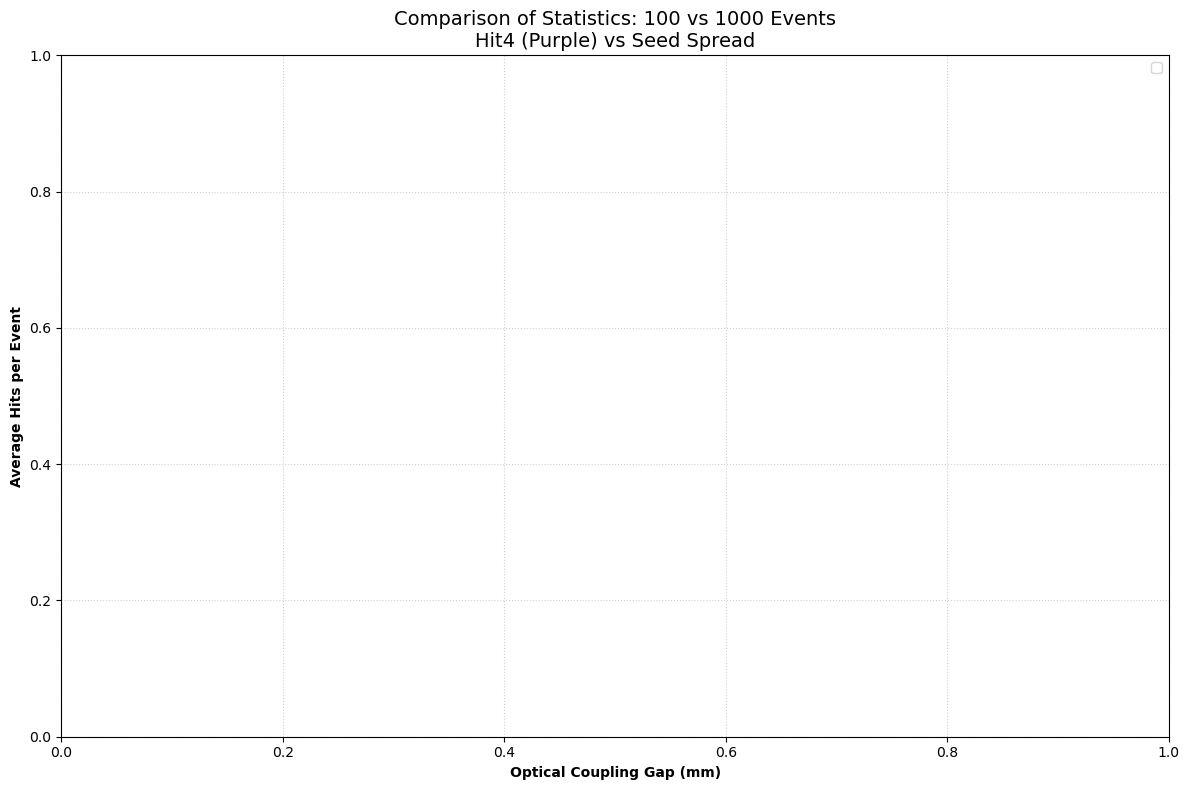

In [7]:
import uproot
import glob
import re
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

# --- CONFIGURATION ---
WLS = "KR"
REF = "1"
TAU = "1.5"
FIXED_SIZE = 250
FIXED_THICK = 20

DATA_CONFIGS = {
    "Hit1": {"runs": 100, "dir": "100Runs"},
    "Hit2": {"runs": 100, "dir": "100Runs"},
    "Hit3": {"runs": 100, "dir": "100Runs"},
    "Hit4": {"runs": 1000, "dir": "1000Runs"} 
}

def get_data_for_type(data_type, n_events, folder):
    file_pattern = f"/scratch/alice/j/jss55/G4Data/{folder}/WLS_{WLS}_Ref_{REF}_{data_type}_Gap_*mm_Size_{FIXED_SIZE}mm_Thick_{FIXED_THICK}mm_Tau_{TAU}ns.root"
    regex_parser = re.compile(r"Gap_([\d\.]+)mm")
    files = glob.glob(file_pattern)
    data_dict = {}
    for f in files:
        match = regex_parser.search(f)
        if not match: continue
        gap_val = float(match.group(1))
        try:
            with uproot.open(f) as root_f:
                tree_name = "DetPhotons" if "DetPhotons" in root_f else list(root_f.keys())[0].split(';')[0]
                times = root_f[tree_name]["fT"].array(library="np")
                data_dict[gap_val] = len(times) / n_events
        except Exception: continue
    return data_dict

# --- DATA PROCESSING ---
all_results = defaultdict(list)
type_results = {}

for t, config in DATA_CONFIGS.items():
    data = get_data_for_type(t, config["runs"], config["dir"])
    if data:
        type_results[t] = data
        # Only aggregate 100Runs for the mean/error calculation
        if config["runs"] == 100:
            for gap, hits in data.items():
                all_results[gap].append(hits)

# --- CRITICAL FIX: Only use gaps that have 100-run data ---
# We sort only the gaps that have entries in all_results
stats_gaps = np.array(sorted(all_results.keys()))
mean_hits = []
sigma_obs = [] 

for gap in stats_gaps:
    values = all_results[gap]
    mean_hits.append(np.mean(values))
    # If only 1 seed exists for a gap, std is 0. 
    # Better to have at least 2 for a real error bar.
    sigma_obs.append(np.std(values) if len(values) > 1 else 0)

mean_hits = np.array(mean_hits)
sigma_obs = np.array(sigma_obs)

# --- PLOTTING ---
plt.figure(figsize=(12, 8))

# 1. Plot Hit1, Hit2, Hit3 (Raw Seeds)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
for i, t in enumerate(["Hit1", "Hit2", "Hit3"]):
    if t in type_results:
        g = sorted(type_results[t].keys())
        h = [type_results[t][k] for k in g]
        plt.plot(g, h, 'o--', alpha=0.3, color=colors[i], label=f"{t} (N=100)")

# 2. Plot Hit4 (N=1000) - This uses its own gap list
if "Hit4" in type_results:
    g4 = sorted(type_results["Hit4"].keys())
    h4 = [type_results["Hit4"][k] for k in g4]
    plt.plot(g4, h4, 's-', color='purple', linewidth=2, markersize=8, label="Hit4 (N=1000)", zorder=5)

# 3. Plot Mean and Observed Spread (Match stats_gaps to mean_hits)
if len(stats_gaps) > 0:
    plt.fill_between(stats_gaps, mean_hits - sigma_obs, mean_hits + sigma_obs, 
                     color='gray', alpha=0.2, label="1$\sigma$ Seed Variation")

    plt.errorbar(stats_gaps, mean_hits, yerr=2*sigma_obs, fmt='o-', 
                 color='black', ecolor='red', elinewidth=1.5, capsize=6, 
                 markersize=4, label="Mean (N=100) $\pm$ 2$\sigma$")

# --- AESTHETICS ---
plt.title(f"Comparison of Statistics: 100 vs 1000 Events\nHit4 (Purple) vs Seed Spread", fontsize=14)
plt.xlabel("Optical Coupling Gap (mm)", fontweight='bold')
plt.ylabel("Average Hits per Event", fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='best', frameon=True)

plt.tight_layout()
plt.show()

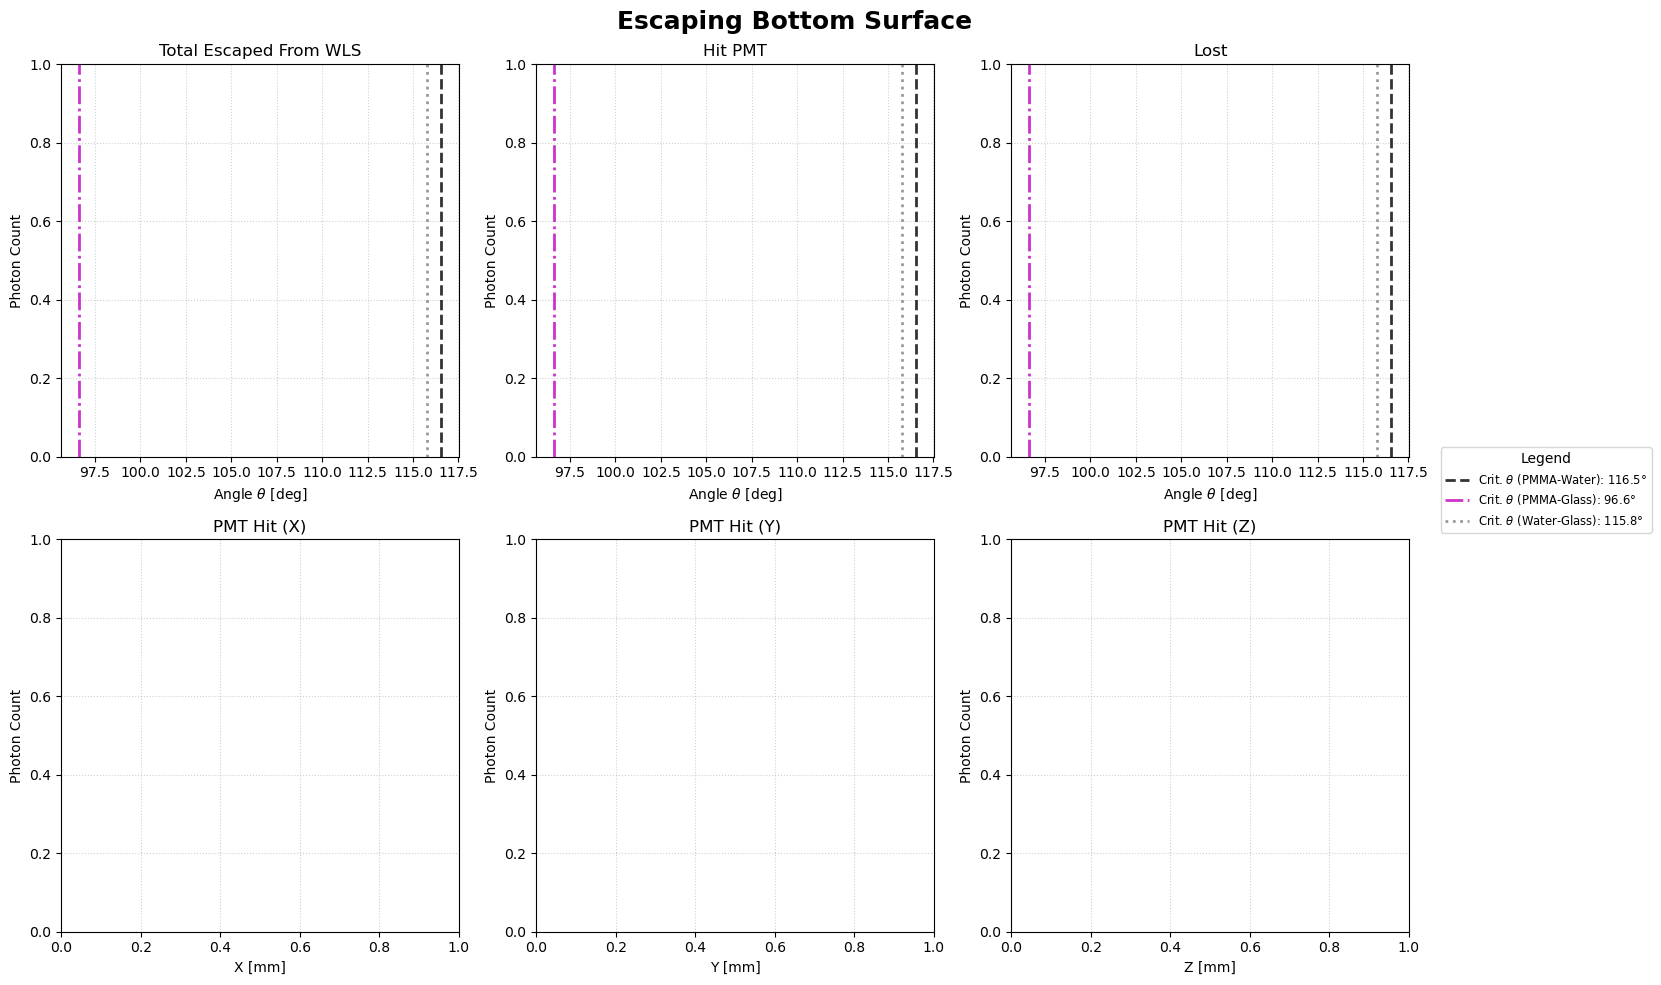

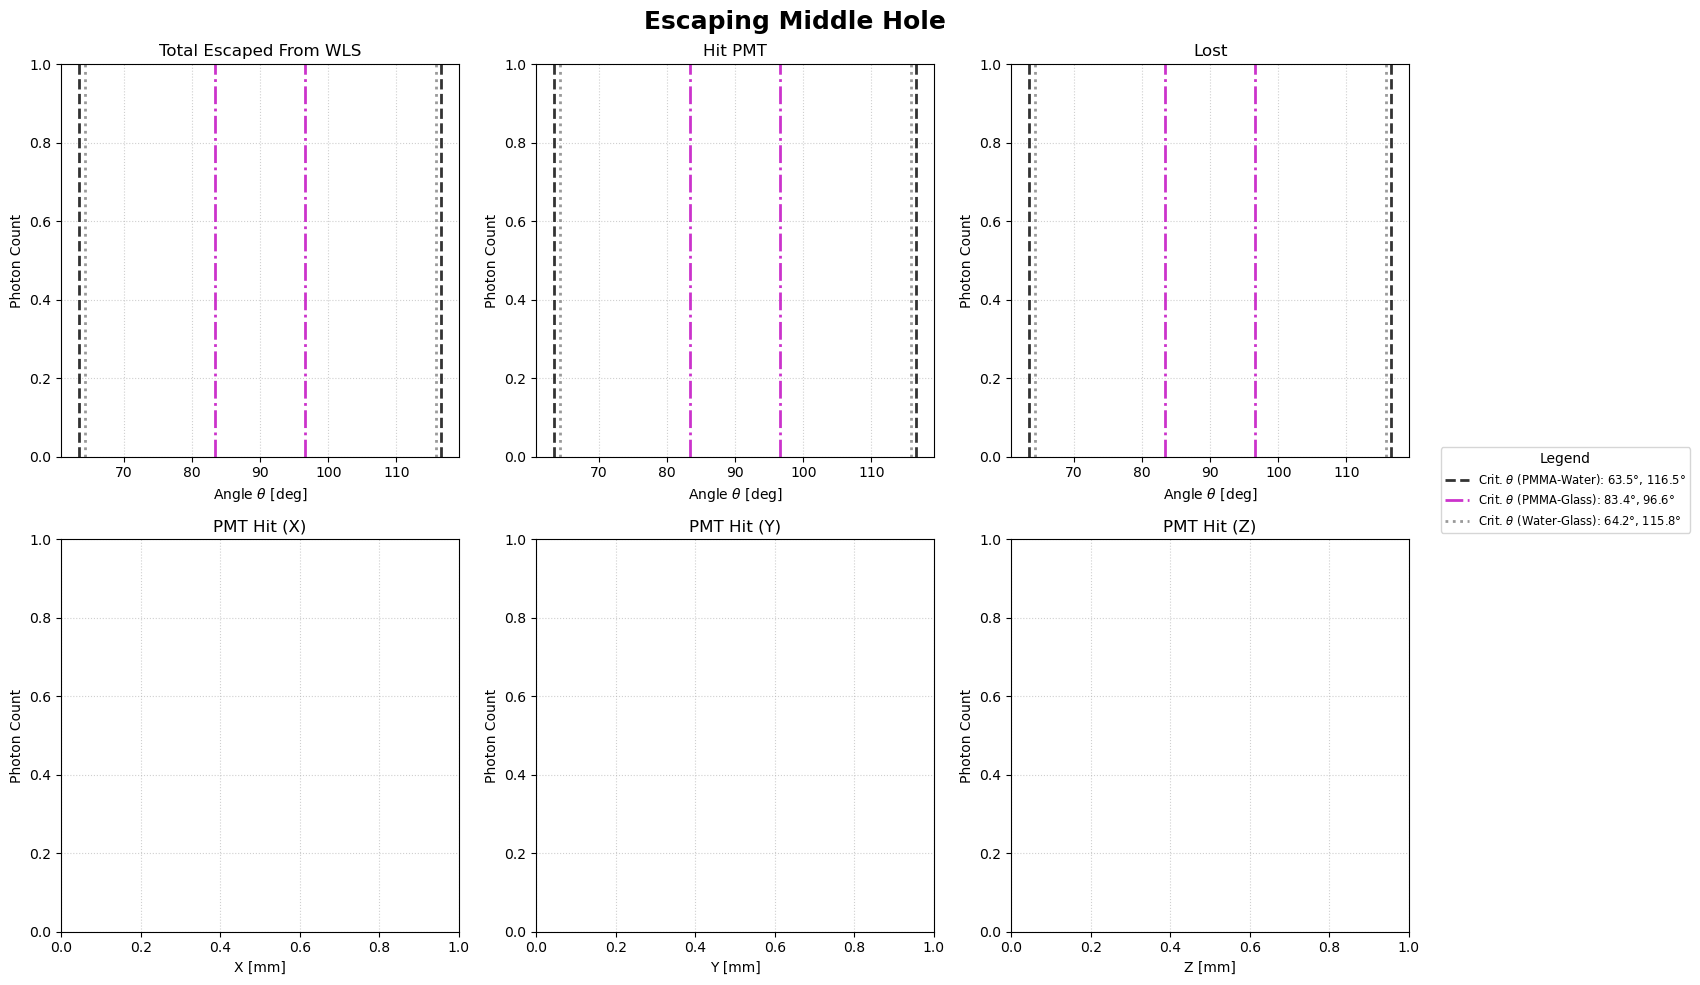

In [10]:
import glob
import uproot
import numpy as np
import matplotlib.pyplot as plt

crit_pw = np.degrees(np.arcsin(1.333 / 1.49))
crit_pg = np.degrees(np.arcsin(1.48 / 1.49))
crit_wg = np.degrees(np.arcsin(1.333 / 1.48))

WLS, REF, TAU = "KR", "Real", "1.5"
SIZE, THICK = 400, 10
GAPS = [0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4]
Y_MAX = 488

def get_data(gap, mode):
    res = {k: [] for k in ["total", "det", "undet", "x", "y", "z"]}
    pattern = f"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_{WLS}_Ref_{REF}_Hit_Gap_{gap}mm_Size_{SIZE}mm_Thick_{THICK}mm_Tau_{TAU}ns.root"
    
    for f in glob.glob(pattern):
        with uproot.open(f) as root_f:
            keys = [x.split(';')[0] for x in root_f.keys()]
            if "DetPhotons" not in keys: 
                continue
            
            det_keys = [x.split(';')[0] for x in root_f["DetPhotons"].keys()]
            has_py = "fPy" in det_keys
            cols = ["fEvent", "fTrackEvent", "fX", "fY", "fZ"] + (["fPy"] if has_py else [])
            det = root_f["DetPhotons"].arrays(cols, library="np")
            
            if gap == 0 and mode == 'hole':
                mask = det["fY"] >= (Y_MAX - 1e-4)
                if has_py:
                    angles = np.degrees(np.arccos(det["fPy"][mask]))
                    
                    # FILTER: Enforce TIR trapping to exclude direct Cherenkov background.
                    # True WLS photons must be trapped by TIR to reach the hole, bounding them 
                    # strictly between the PMMA-Water critical angles.
                    tir_mask = (angles >= crit_pw) & (angles <= (180 - crit_pw))
                    
                    res["total"].append(angles[tir_mask])
                    res["det"].append(angles[tir_mask])
                    res["x"].append(det["fX"][mask][tir_mask])
                    res["y"].append(det["fY"][mask][tir_mask])
                    res["z"].append(det["fZ"][mask][tir_mask])
                else:
                    res["x"].append(det["fX"][mask])
                    res["y"].append(det["fY"][mask])
                    res["z"].append(det["fZ"][mask])
                continue

            if "EscapedPhotons" not in keys: 
                continue
                
            esc = root_f["EscapedPhotons"].arrays(["fEvent", "fTrackEvent", "fY", "fPy"], library="np")
            
            if mode == 'bottom':
                esc_mask = np.isclose(esc["fY"], Y_MAX, atol=1e-4) & (esc["fPy"] < 0)
            else:
                esc_mask = esc["fY"] > (Y_MAX + 1e-4)

            det_ids = (det["fEvent"].astype(np.int64) << 32) | det["fTrackEvent"].astype(np.int64)
            esc_ids = (esc["fEvent"][esc_mask].astype(np.int64) << 32) | esc["fTrackEvent"][esc_mask].astype(np.int64)
            
            angles = np.degrees(np.arccos(esc["fPy"][esc_mask]))
            is_det = np.isin(esc_ids, det_ids)
            hit_pmt = np.isin(det_ids, esc_ids)

            res["total"].append(angles)
            res["det"].append(angles[is_det])
            res["undet"].append(angles[~is_det])
            res["x"].append(det["fX"][hit_pmt])
            res["y"].append(det["fY"][hit_pmt])
            res["z"].append(det["fZ"][hit_pmt])

    return [np.concatenate(res[k]) if len(res[k]) > 0 else np.array([]) for k in res]

colors = {g: plt.get_cmap('tab10')(i % 10) for i, g in enumerate(GAPS)}
modes = {'bottom': 'Escaping Bottom Surface', 'hole': 'Escaping Middle Hole'}
titles = ["Total Escaped From WLS", "Hit PMT", "Lost", "PMT Hit (X)", "PMT Hit (Y)", "PMT Hit (Z)"]
xlabels = [r"Angle $\theta$ [deg]"] * 3 + ["X [mm]", "Y [mm]", "Z [mm]"]

for mode, title in modes.items():
    fig, axs = plt.subplots(2, 3, figsize=(16, 10))
    fig.suptitle(title, fontsize=18, fontweight='bold')
    
    for i, (ax, t, xl) in enumerate(zip(axs.flat, titles, xlabels)):
        ax.set(title=t, xlabel=xl, ylabel="Photon Count")
        ax.grid(True, linestyle=':', alpha=0.6)
        
        # Add critical angle lines to the first 3 angle plots dynamically based on mode
        if i < 3:
            if mode == 'bottom':
                # Downward-only escape cone lines (180 - crit_angle)
                ax.axvline(180 - crit_pw, color='k', linestyle='--', lw=2, alpha=0.8, label=f'Crit. $\\theta$ (PMMA-Water): {180-crit_pw:.1f}°')
                ax.axvline(180 - crit_pg, color='m', linestyle='-.', lw=2, alpha=0.8, label=f'Crit. $\\theta$ (PMMA-Glass): {180-crit_pg:.1f}°')
                ax.axvline(180 - crit_wg, color='gray', linestyle=':', lw=2, alpha=0.8, label=f'Crit. $\\theta$ (Water-Glass): {180-crit_wg:.1f}°')
            else:
                # Upward AND Downward limits for symmetric horizontal escapes
                ax.axvline(crit_pw, color='k', linestyle='--', lw=2, alpha=0.8, label=f'Crit. $\\theta$ (PMMA-Water): {crit_pw:.1f}°, {180-crit_pw:.1f}°')
                ax.axvline(180 - crit_pw, color='k', linestyle='--', lw=2, alpha=0.8)
                
                ax.axvline(crit_pg, color='m', linestyle='-.', lw=2, alpha=0.8, label=f'Crit. $\\theta$ (PMMA-Glass): {crit_pg:.1f}°, {180-crit_pg:.1f}°')
                ax.axvline(180 - crit_pg, color='m', linestyle='-.', lw=2, alpha=0.8)
                
                ax.axvline(crit_wg, color='gray', linestyle=':', lw=2, alpha=0.8, label=f'Crit. $\\theta$ (Water-Glass): {crit_wg:.1f}°, {180-crit_wg:.1f}°')
                ax.axvline(180 - crit_wg, color='gray', linestyle=':', lw=2, alpha=0.8)

    for g in GAPS:
        for i, (ax, data) in enumerate(zip(axs.flat, get_data(g, mode))):
            if len(data):
                rng = (0, 180) if i < 3 else None
                ax.hist(data, bins=100, range=rng, histtype='step', lw=2, color=colors[g], label=f"{g} mm")

    handles, labels = axs.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Legend", loc='center left', bbox_to_anchor=(0.9, 0.5), fontsize='small')
    plt.tight_layout(rect=[0, 0, 0.9, 1])

plt.show()

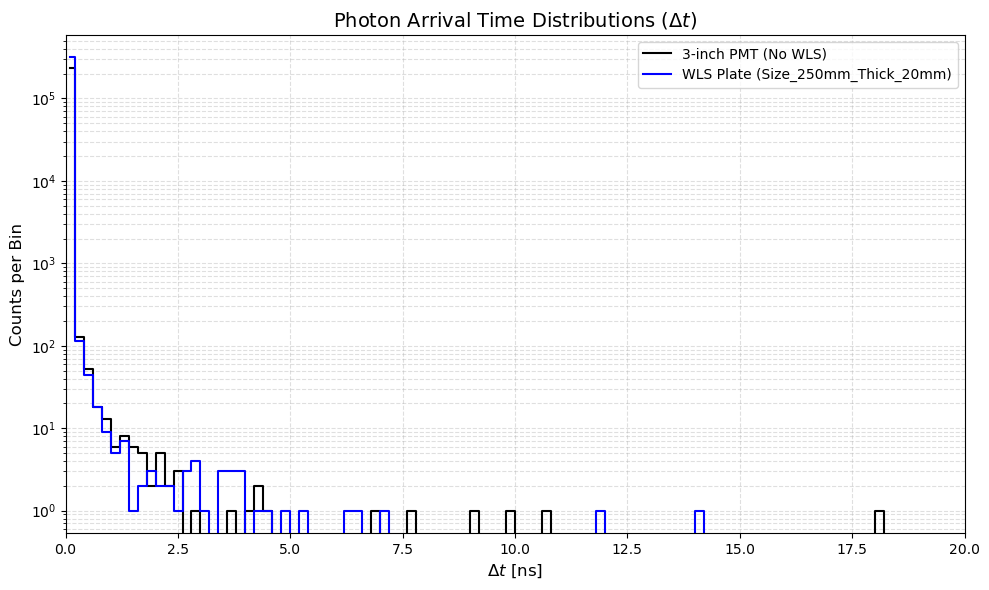

In [13]:
import uproot
import glob
import os
import numpy as np
import matplotlib.pyplot as plt


path_no_wls = "/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/3-inchPMT_Ref_Real_Hit1.root"
path_wls = "/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_KR_Ref_Real_Hit1_Gap_0mm_Size_400mm_Thick_10mm_Tau_1.5ns.root"

def get_dt_data(file_path):
        
    with uproot.open(file_path) as rf:

        tree_keys = [k.split(';')[0] for k in rf.keys()]
        tree_name = "DetPhotons" if "DetPhotons" in tree_keys else tree_keys[0]
        
        # Load time array
        t_raw = rf[tree_name]["fT"].array(library="np")
    
    if len(t_raw) < 2:
        return np.array([])

    # Calculate dt between consecutive hits
    t_sorted = np.sort(t_raw)
    dt = np.diff(t_sorted)
    
    # Filter for the 0-10ns window
    return dt[(dt > 0) & (dt <= 20)]


dt_no_wls = get_dt_data(path_no_wls)
dt_wls = get_dt_data(path_wls)


plt.figure(figsize=(10, 6))

plot_configs = [
    (dt_no_wls, 'black', '3-inch PMT (No WLS)'),
    (dt_wls, 'blue', f'WLS Plate (Size_250mm_Thick_20mm)')
]


for data, color, label in plot_configs:
    if data is not None and len(data) > 0:
        counts, edges = np.histogram(data, bins=100, range=(0, 20))
        centers = (edges[:-1] + edges[1:]) / 2
        
        plt.step(centers, counts, where='mid', color=color, lw=1.5, label=label)
        
        if len(counts) > 0:
            max_counts = max(1, np.max(counts))


plt.yscale('log')
plt.xlim(0, 20)

plt.xlabel(r'$\Delta t$ [ns]', fontsize=12)
plt.ylabel('Counts per Bin', fontsize=12)
plt.title('Photon Arrival Time Distributions ($\Delta t$)', fontsize=14)
plt.legend(frameon=True, loc='upper right')
plt.grid(True, which="both", linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [2]:
import uproot
import glob
import re
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict
import concurrent.futures
import os

# --- CONFIGURATION ---
N_EVENTS = 5000       
MANUAL_CUT_TIME = 20.0   
WLS = "KR"
REF = "Real"
TAU = "1.5"
TYPES = ["Hit1", "Hit2", "Hit3"]
DATA_DIR = "/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/"

MAX_WORKERS = 8 # Increased slightly; uproot.arrays is efficient with memory

# --- OPTIMIZED WORKER FUNCTION ---
def process_wls_file(file_info):
    """Processes WLS files using a single-pass array read."""
    f, t_seed = file_info
    
    # Fast filename parsing
    try:
        match = re.search(r"_Size_(\d+)mm_Thick_(\d+)mm", f)
        if not match: return None
        size_val, thick_val = int(match.group(1)), int(match.group(2))
        
        with uproot.open(f) as root_f:
            # 1. Process Detection Timing & Reflections
            det_tree = root_f.get("DetPhotons") or next(iter(root_f.values()))
            # Read all needed branches at once into a dict of numpy arrays
            det_data = det_tree.arrays(["fT", "fReflections"], library="np")
            
            mask = det_data["fT"] < MANUAL_CUT_TIME
            valid_times = det_data["fT"][mask]
            valid_refs = det_data["fReflections"][mask] if "fReflections" in det_data else None
            
            # 2. Process Absorption Efficiency
            n_abs = 0
            if "AbsPhotons" in root_f:
                abs_vols = root_f["AbsPhotons"]["fPostVolumeID"].array(library="np")
                n_abs = np.count_nonzero(abs_vols == 1)
            
            n_emm = root_f["EmmPhotons"].num_entries if "EmmPhotons" in root_f else 0
            
            return {
                'type': 'wls', 'size': size_val, 'thick': thick_val, 
                'hits': len(valid_times), 'times': valid_times, 'refs': valid_refs,
                'abs': n_abs, 'emm': n_emm
            }
    except Exception as e:
        print(f"Error processing {os.path.basename(f)}: {e}")
        return None

if __name__ == '__main__':
    print(f"Starting Optimized Analysis...")

    # --- 1. VECTORIZED REFERENCE FILE PROCESSING ---
    # We bypass the ProcessPool for refs because uproot.concatenate is faster
    print("Reading Reference PMT data (Vectorized)...")
    pmt_results = []
    ref_configs = [{"l": "3-inch", "c": "red"}, {"l": "5-inch", "c": "blue"}, {"l": "8-inch", "c": "green"}]
    
    for p in ref_configs:
        ref_paths = [f"{DATA_DIR}{p['l']}PMT_Ref_{REF}_{t}.root" for t in TYPES]
        # Filter for existing files only
        valid_paths = [path for path in ref_paths if os.path.exists(path)]
        
        if not valid_paths: continue

        # Concatenate all "Hit" types for this PMT size into one array instantly
        # Syntax: "file.root:TreeName"
        all_ref_data = uproot.concatenate([f"{path}:DetPhotons" for path in valid_paths], ["fT"], library="np")
        t_filter = all_ref_data["fT"] < MANUAL_CUT_TIME
        valid_t = all_ref_data["fT"][t_filter]
        
        pmt_results.append({
            'l': p['l'], 'c': p['c'], 
            'hits': len(valid_t), 
            'times': valid_t, 
            'seeds_found': len(valid_paths)
        })

    # --- 2. PARALLEL WLS PROCESSING ---
    wls_tasks = []
    for t in TYPES:
        pattern = f"{DATA_DIR}WLS_{WLS}_Ref_{REF}_{t}_Gap_0mm_Size_*mm_Thick_*mm_Tau_{TAU}ns.root"
        for f in glob.glob(pattern):
            wls_tasks.append((f, t))

    print(f"Processing {len(wls_tasks)} WLS files with {MAX_WORKERS} workers...")
    with concurrent.futures.ProcessPoolExecutor(max_workers=MAX_WORKERS) as executor:
        wls_raw = list(executor.map(process_wls_file, wls_tasks))

    # --- 3. AGGREGATION ---
    wls_grouped = defaultdict(lambda: {'hits': 0, 'seeds': 0, 'times_list': [], 'refs_list': [], 'abs': 0, 'emm': 0})
    for res in filter(None, wls_raw):
        key = (res['size'], res['thick'])
        wls_grouped[key]['hits'] += res['hits']
        wls_grouped[key]['seeds'] += 1
        wls_grouped[key]['times_list'].append(res['times'])
        wls_grouped[key]['abs'] += res['abs']
        wls_grouped[key]['emm'] += res['emm']
        if res['refs'] is not None: wls_grouped[key]['refs_list'].append(res['refs'])

    # --- 4. DATA STRUCTURING ---
    data_points = []
    baseline_3in = next((p['hits']/p['seeds_found'] for p in pmt_results if p['l'] == "3-inch"), 0)

    for (size, thick), data in wls_grouped.items():
        avg_hits = data['hits'] / data['seeds']
        data_points.append({
            'size': size, 'thick': thick, 'hits': avg_hits,
            'hits_per_evt': avg_hits / N_EVENTS,
            'vol_liters': (size**2 * thick) * 1e-6,
            'eff': (data['emm'] / data['abs']) if data['abs'] > 0 else 0,
            'times': np.concatenate(data['times_list']) if data['times_list'] else np.array([]),
            'reflections': np.concatenate(data['refs_list']) if data['refs_list'] else None,
            'seeds_found': data['seeds'],
            'factor_3in': avg_hits / baseline_3in if baseline_3in > 0 else 1.0,
            'perc_3in': ((avg_hits / baseline_3in) - 1) * 100 if baseline_3in > 0 else 0
        })

    # Sort for plotting
    data_points = sorted(data_points, key=lambda x: (x['thick'], x['size']))
    unique_sizes = sorted(list(set(d['size'] for d in data_points)))
    unique_thicks = sorted(list(set(d['thick'] for d in data_points)))

    # --- 5. PLOTTING ---
    def get_grid(attr):
        grid = np.full((len(unique_thicks), len(unique_sizes)), np.nan)
        for d in data_points:
            grid[unique_thicks.index(d['thick']), unique_sizes.index(d['size'])] = d[attr]
        return grid

    # Heatmap: Enhancement Factor
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(get_grid('factor_3in'), origin='lower', cmap='viridis', aspect='auto')
    ax.set_xticks(range(len(unique_sizes))); ax.set_xticklabels(unique_sizes)
    ax.set_yticks(range(len(unique_thicks))); ax.set_yticklabels(unique_thicks)
    ax.set_title(f"Enhancement Factor vs 3-inch PMT\n({WLS} WLS, {MANUAL_CUT_TIME}ns window)")
    for i, t in enumerate(unique_thicks):
        for j, s in enumerate(unique_sizes):
            val = get_grid('factor_3in')[i, j]
            if not np.isnan(val): ax.text(j, i, f"{val:.2f}x", ha="center", va="center", color="white", fontweight='bold')
    plt.colorbar(im, label="Factor Increase"); plt.show()

    # Timing Distribution
    fig, ax = plt.subplots(figsize=(10, 6))
    for p in pmt_results:
        pt = np.sort(p['times'])
        if len(pt) > 0: ax.step(pt, np.arange(len(pt))/p['seeds_found'], color=p['c'], label=f"Ref {p['l']}")
    
    best_wls = max(data_points, key=lambda x: x['hits'])
    wt = np.sort(best_wls['times'])
    ax.step(wt, np.arange(len(wt))/best_wls['seeds_found'], color='black', linewidth=2, label=f"Best WLS ({best_wls['size']}x{best_wls['thick']}mm)")
    
    ax.set_yscale('log'); ax.set_xlabel("Time (ns)"); ax.set_ylabel("Average Hits per Seed")
    ax.set_title("Cumulative Arrival Distribution"); ax.legend(); ax.grid(which='both', alpha=0.2)
    plt.show()

    print("Analysis Complete.")

Starting Optimized Analysis...
Reading Reference PMT data (Vectorized)...


KeyboardInterrupt: 

Found 120 files. Sorting into datasets...


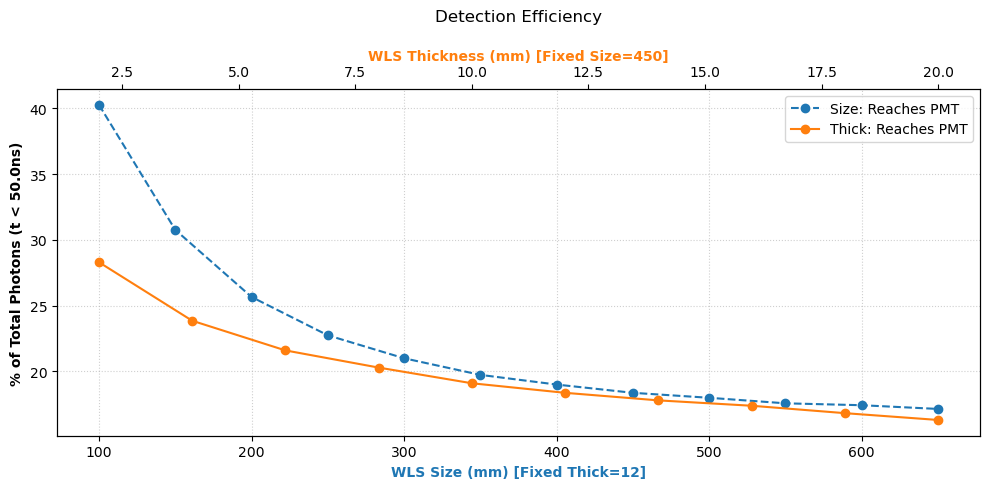

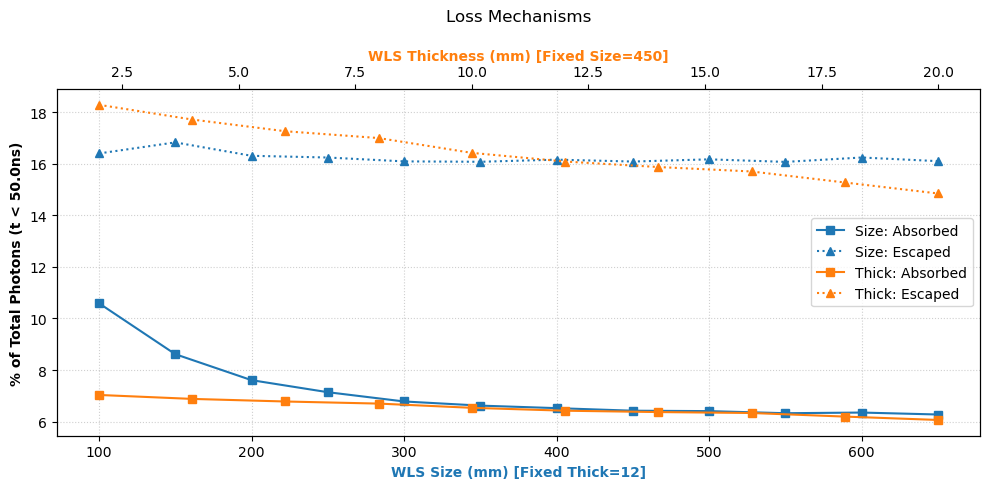

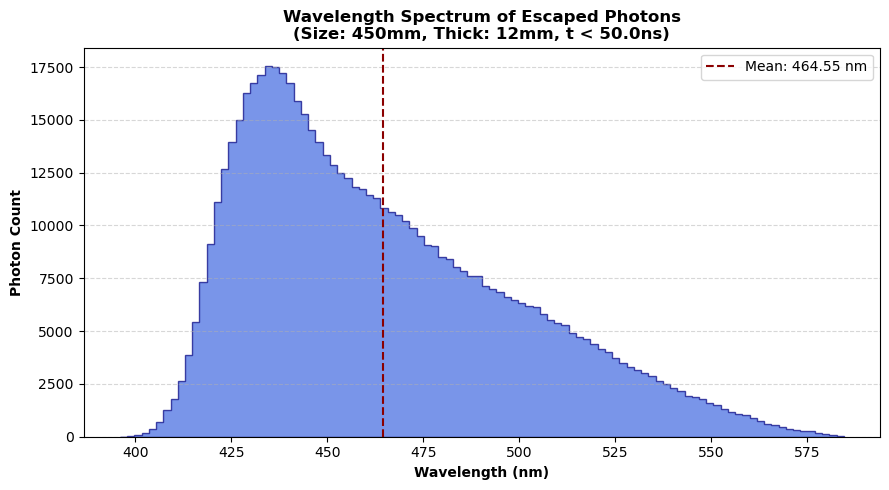

In [14]:
import uproot
import glob
import re
import numpy as np
import matplotlib.pyplot as plt

# --- CONFIGURATION ---
DATA_DIR = "/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/" 
TIME_WINDOW = 50.0  # ns
WLS = "KR"
REF = "Real"
TYPE = "Hit5"
TAU = "1.5"

# --- FIXED PARAMETERS FOR SCANS ---
FIXED_SIZE_VAL = 450 
FIXED_THICK_VAL = 12

# --- DATA ACQUISITION ---
file_pattern = f"{DATA_DIR}WLS_{WLS}_Ref_{REF}_{TYPE}_Gap_0mm_Size_*mm_Thick_*mm_Tau_{TAU}ns.root"
regex_parser = re.compile(fr"_{TYPE}_Gap_0mm_Size_(\d+)mm_Thick_(\d+)mm")

files = glob.glob(file_pattern)

if not files:
    print(f"No files found matching: {file_pattern}")
else:
    print(f"Found {len(files)} files. Sorting into datasets...")

data_thick_var = [] 
data_size_var = []  
# Store wavelengths for the specific reference geometry point
ref_escaped_wavelengths = np.array([])

for f in sorted(files):
    match = regex_parser.search(f)
    if not match: continue
    
    size_val = int(match.group(1))
    thick_val = int(match.group(2))
    
    is_thick_var = (size_val == FIXED_SIZE_VAL)
    is_size_var = (thick_val == FIXED_THICK_VAL)

    if not is_thick_var and not is_size_var: continue
    
    try:
        with uproot.open(f) as file:
            # 1. Total Births
            n_births = file["EmmPhotons"].num_entries if "EmmPhotons" in file else 0
            if n_births == 0: continue

            # 2. WLSPhotons
            wls_tree = file["WLSPhotons"]
            if wls_tree.num_entries == 0:
                raw_procs, wls_times = np.array([]), np.array([])
            else:
                wls_data = wls_tree.arrays(["fProcessName", "fGlobalTime"], library="np")
                raw_procs, wls_times = wls_data["fProcessName"], wls_data["fGlobalTime"]

            # 3. EscapedPhotons
            esc_tree = file["EscapedPhotons"]
            if esc_tree.num_entries == 0:
                esc_times, esc_wl = np.array([]), np.array([])
            else:
                # UPDATED: Using 'fwlen' branch as requested
                esc_data = esc_tree.arrays(["fGlobalTime", "fwlen"], library="np")
                esc_times = esc_data["fGlobalTime"]
                esc_wl = esc_data["fwlen"]

            # --- PROCESS KEYS ---
            unique_procs = np.unique(raw_procs) if len(raw_procs) > 0 else []
            trans_key = next((k for k in unique_procs if k in [b"Transportation", "Transportation"]), None)
            abs_key   = next((k for k in unique_procs if k in [b"OpAbsorption", "OpAbsorption"]), None)

            # --- APPLY TIME CUT ---
            mask_wls = wls_times <= TIME_WINDOW
            procs_in_window = raw_procs[mask_wls]
            mask_esc = esc_times <= TIME_WINDOW
            
            # Save wavelengths for the reference point (central overlap of the two scans)
            if size_val == FIXED_SIZE_VAL and thick_val == FIXED_THICK_VAL:
                ref_escaped_wavelengths = esc_wl[mask_esc]

            # --- CALCULATE COUNTS ---
            n_det = np.sum(procs_in_window == trans_key) if trans_key is not None else 0
            n_esc_loss = np.sum(mask_esc)
            n_absorbed = np.sum(procs_in_window == abs_key) if abs_key is not None else 0

            entry = {
                "size": size_val, "thick": thick_val,
                "pct_det": (n_det / n_births) * 100,
                "pct_esc": (n_esc_loss / n_births) * 100,
                "pct_abs": (n_absorbed / n_births) * 100
            }

            if is_thick_var: data_thick_var.append(entry)
            if is_size_var: data_size_var.append(entry)

    except Exception as e:
        print(f"Error processing {f}: {e}")

# --- SORT DATA ---
data_thick_var.sort(key=lambda x: x['thick'])
data_size_var.sort(key=lambda x: x['size'])

# --- PLOTTING ---
if data_thick_var or data_size_var:
    
    def plot_dual_axis(metric_keys, metric_labels, title, colors_size, colors_thick, markers, linestyles, linestyle_mode="dataset"):
        fig, ax1 = plt.subplots(figsize=(10, 5))
        ax2 = ax1.twiny()
        lines = []
        if data_size_var:
            x_size = [d['size'] for d in data_size_var]
            for i, key in enumerate(metric_keys):
                ls = linestyles[i] if linestyle_mode == "metric" else linestyles[0]
                l, = ax1.plot(x_size, [d[key] for d in data_size_var], color=colors_size[i], marker=markers[i], linestyle=ls, label=f"Size: {metric_labels[i]}")
                lines.append(l)
            ax1.set_xlabel(f"WLS Size (mm) [Fixed Thick={FIXED_THICK_VAL}]", fontweight='bold', color=colors_size[0])
        if data_thick_var:
            x_thick = [d['thick'] for d in data_thick_var]
            for i, key in enumerate(metric_keys):
                ls = linestyles[i] if linestyle_mode == "metric" else linestyles[1]
                l, = ax2.plot(x_thick, [d[key] for d in data_thick_var], color=colors_thick[i], marker=markers[i], linestyle=ls, label=f"Thick: {metric_labels[i]}")
                lines.append(l)
            ax2.set_xlabel(f"WLS Thickness (mm) [Fixed Size={FIXED_SIZE_VAL}]", fontweight='bold', color=colors_thick[0])
        ax1.set_ylabel(f"% of Total Photons (t < {TIME_WINDOW}ns)", fontweight='bold')
        ax1.grid(True, linestyle=':', alpha=0.6)
        plt.title(title, pad=20)
        ax1.legend(lines, [l.get_label() for l in lines], loc='best')
        plt.tight_layout()
        plt.show()

    # Efficiency Plots
    plot_dual_axis(["pct_det"], ["Reaches PMT"], "Detection Efficiency", ["#1f77b4"], ["#ff7f0e"], ["o"], ["--", "-"])
    plot_dual_axis(["pct_abs", "pct_esc"], ["Absorbed", "Escaped"], "Loss Mechanisms", ["#1f77b4","#1f77b4"], ["#ff7f0e","#ff7f0e"], ["s","^"], ["-",":"], "metric")

    # --- WAVELENGTH DISTRIBUTION PLOT ---
    if len(ref_escaped_wavelengths) > 0:
        plt.figure(figsize=(9, 5))
        plt.hist(ref_escaped_wavelengths, bins=100, color='royalblue', alpha=0.7, edgecolor='navy', histtype='stepfilled')
        
        plt.title(f"Wavelength Spectrum of Escaped Photons\n(Size: {FIXED_SIZE_VAL}mm, Thick: {FIXED_THICK_VAL}mm, t < {TIME_WINDOW}ns)", fontweight='bold')
        plt.xlabel("Wavelength (nm)", fontweight='bold')
        plt.ylabel("Photon Count", fontweight='bold')
        plt.grid(axis='y', linestyle='--', alpha=0.5)
        
        # Add Mean Annotation
        mean_val = np.mean(ref_escaped_wavelengths)
        plt.axvline(mean_val, color='darkred', linestyle='dashed', label=f'Mean: {mean_val:.2f} nm')
        plt.legend()
        
        plt.tight_layout()
        plt.show()
    else:
        print("Warning: No wavelength data found for the reference geometry point.")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Data from your Thickness Run ---
thickness_mm = np.array([2, 4, 6, 8, 9, 10, 12, 14, 16, 18, 20])
escaped_pct  = np.array([53.26, 52.04, 50.84, 49.78, 49.31, 48.77, 48.01, 46.88, 46.21, 45.35, 44.54])

# --- Define Decay Function ---
# Physics suggests exponential decay towards an asymptote
# y = A * exp(-B * x) + C
def decay_func(x, a, b, c):
    return a * np.exp(-b * x) + c

# --- Fit the Data ---
# Initial guesses: A=10 (range), B=0.01 (slow decay), C=40 (asymptote?)
p0 = [20, 0.05, 30] 
try:
    popt, _ = curve_fit(decay_func, thickness_mm, escaped_pct, p0=p0, maxfev=5000)
except:
    # Fallback to linear if fit fails (unlikely)
    popt = [0, 0, 0]

# --- Generate Projection ---
x_proj = np.linspace(0, 100, 200) # Project out to 100mm
y_proj = decay_func(x_proj, *popt)

# --- Plotting ---
plt.figure(figsize=(10, 6))

# Plot Projection
plt.plot(x_proj, y_proj, 'r--', label=f'Projection (Decay to ~{popt[2]:.1f}%)')
# Plot Your Data
plt.plot(thickness_mm, escaped_pct, 'ks', markersize=8, label='Your Simulation Data')

plt.title("Will it Plateau? Thickness Trend Projection", fontsize=14)
plt.xlabel("Thickness (mm)", fontsize=12)
plt.ylabel("% Escaped", fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()

# Annotation
plt.annotate(f'As thickness increases,\ninternal absorption dominates.\nIt asymptotes to ~{popt[2]:.1f}%', 
             xy=(80, y_proj[-1]), xytext=(40, y_proj[-1] + 5),
             arrowprops=dict(facecolor='black', shrink=0.05))

plt.tight_layout()
plt.show()

In [ ]:
import uproot
import numpy as np
import matplotlib.pyplot as plt

# --- CONFIGURATION ---
# Set this to the exact path of the ONE file you want to analyze
TARGET_FILE = "/scratch/alice/j/jss55/G4Data/NewMuonGen_100Ref_PolishedWLSPMTBound_SolidPMT/WLS_KR_Ref_100_Hit_Gap_0mm_Size_550mm_Thick_10mm_Tau_1.5ns.root"
TREE_NAME = "Muons"

print(f"Reading file: {TARGET_FILE}")

# --- LOAD DATA ---
try:
    with uproot.open(TARGET_FILE) as f:
        if TREE_NAME not in f:
            print(f"Error: '{TREE_NAME}' tree not found in the file.")
            exit()
        
        tree = f[TREE_NAME]
        
        # ADDED: Loaded 'fY' to get the vertical starting position
        data = tree.arrays(["fX", "fY", "fZ", "fXMom", "fYMom", "fZMom", "ftheta", "fphi"], library="np")
        
        x = data["fX"]
        y = data["fY"]
        z = data["fZ"]
        px = data["fXMom"]
        py = data["fYMom"]
        pz = data["fZMom"]
        theta = data["ftheta"]
        phi = data["fphi"]
        
        n_muons = len(x)
        print(f"Successfully loaded {n_muons} muons.")

except Exception as e:
    print(f"Failed to load data: {e}")
    exit()

# --- PLOTTING ---
fig = plt.figure(figsize=(18, 5))

# 1. X-Z Position Map (The "Rainfall" area)
ax1 = fig.add_subplot(131)
# cmin=1 makes areas with 0 muons transparent/white
h1 = ax1.hist2d(x, z, bins=50, cmap='viridis', cmin=1)
ax1.set_title("Muon Injection Origin (X-Z Plane)")
ax1.set_xlabel("X Position (mm)")
ax1.set_ylabel("Z Position (mm)")
ax1.set_aspect('equal')
plt.colorbar(h1[3], ax=ax1, label="Muon Count")

# 2. Angular Distribution (Theta vs Phi)
ax2 = fig.add_subplot(132)
h2 = ax2.hist2d(phi, theta, bins=40, cmap='plasma', cmin=1)
ax2.set_title("Momentum Angles ($\phi$ vs $\\theta$)")
ax2.set_xlabel("Azimuthal Angle $\phi$ (radians)")
ax2.set_ylabel("Polar Angle $\\theta$ (radians)")
plt.colorbar(h2[3], ax=ax2, label="Muon Count")

# 3. 3D Trajectory Vectors
ax3 = fig.add_subplot(133, projection='3d')

# Plot a maximum of 500 vectors so the 3D plot doesn't become an unreadable blob
max_vectors = min(n_muons, 500) 

# Map Geant4 coordinates to Matplotlib 3D axes
# Geant4: X, Y (vertical), Z
# Matplotlib 3D standard viewing: X, Y (depth), Z (vertical)
# So we map: X -> X, Z -> Y, Y -> Z
start_x = x[:max_vectors]
start_y = z[:max_vectors]  # G4 Z maps to plot depth
start_z = y[:max_vectors]  # G4 Y maps to plot height

dir_x = px[:max_vectors]
dir_y = pz[:max_vectors]
dir_z = py[:max_vectors]

# Set length=500.0 so the arrows stretch from injection (Y=499mm) down to the bottom
ax3.quiver(start_x, start_y, start_z, 
           dir_x, dir_y, dir_z, 
           length=500.0, normalize=True, alpha=0.4, color='royalblue')

ax3.set_title(f"3D Muon Trajectories\n(Sample of {max_vectors} Muons)")
ax3.set_xlabel("X Position (mm)")
ax3.set_ylabel("Z Position (mm)")
ax3.set_zlabel("Y Position (mm) [Vertical]")

# Set bounds to match your physical 3.8m x 3.8m area 
# and the 500mm height
ax3.set_xlim([-2000, 2000])
ax3.set_ylim([-2000, 2000])
ax3.set_zlim([0, 600]) 

plt.tight_layout()
plt.show()

Scanning for file with highest count in 'EscapedPhotons'...
Pattern: /scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_KR_Ref_Real_Hit2_Gap_0mm_Size_*mm_Thick_*mm_Tau_1.5ns.root
-> Selected: Size 800mm, Thick 20mm
-> File: /scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_KR_Ref_Real_Hit2_Gap_0mm_Size_800mm_Thick_20mm_Tau_1.5ns.root
-> Photons: 6934847


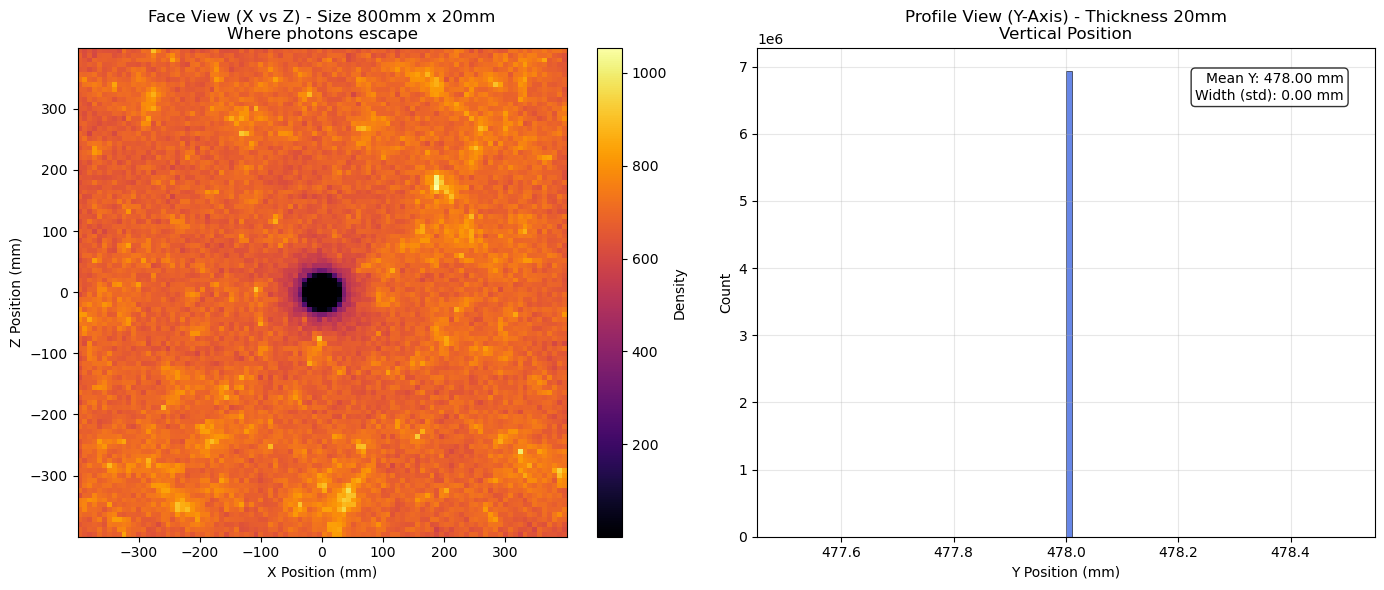

In [1]:
import uproot
import glob
import re
import matplotlib.pyplot as plt
import numpy as np

# --- CONFIGURATION ---
DATA_DIR = "/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/"  # Set your data directory if needed
WLS = "KR"
REF = "Real"
TYPE = "Hit2"   # Ensure this matches your filenames (e.g., 'Hit' vs 'Det')
TAU = "1.5"
TREE_NAME = "EscapedPhotons"
BINS = 100

# Updated Pattern: Wildcard for BOTH Size and Thickness
FILE_PATTERN = f"{DATA_DIR}WLS_{WLS}_Ref_{REF}_{TYPE}_Gap_0mm_Size_*mm_Thick_*mm_Tau_{TAU}ns.root"

print(f"Scanning for file with highest count in '{TREE_NAME}'...")
print(f"Pattern: {FILE_PATTERN}")

# --- 1. FIND BEST FILE ---
files = glob.glob(FILE_PATTERN)
best_file = {"name": None, "count": -1, "size": None, "thick": None}

# Regex to extract params for the title
name_parser = re.compile(r"Size_(\d+)mm_Thick_(\d+)mm")

for fname in files:
    try:
        with uproot.open(fname) as f:
            if TREE_NAME in f:
                n = f[TREE_NAME].num_entries
                
                # Check if this is the new 'best' (highest statistics)
                if n > best_file["count"]:
                    # Parse dimensions
                    match = name_parser.search(fname)
                    s = match.group(1) if match else "?"
                    t = match.group(2) if match else "?"
                    
                    best_file = {
                        "name": fname, 
                        "count": n,
                        "size": s,
                        "thick": t
                    }
    except Exception as e:
        # print(f"Skipping {fname}: {e}")
        pass

if not best_file["name"]:
    print("No valid files found.")
    exit()

print(f"-> Selected: Size {best_file['size']}mm, Thick {best_file['thick']}mm")
print(f"-> File: {best_file['name']}")
print(f"-> Photons: {best_file['count']}")

# --- 2. LOAD DATA ---
with uproot.open(best_file["name"]) as f:
    # Check if keys exist
    keys = f[TREE_NAME].keys()
    # Handle potential naming variations (fX vs fPosition.X etc)
    # Assuming standard fX, fY, fZ from context
    data = f[TREE_NAME].arrays(["fX", "fY", "fZ"], library="np")
    x = data["fX"]
    y = data["fY"]
    z = data["fZ"]

# --- 3. PLOT ---
fig = plt.figure(figsize=(14, 6))

# Subplot 1: X-Z Heatmap (The "Face")
ax1 = fig.add_subplot(121)
ax1.set_facecolor('black') 

# cmin=1 makes empty bins transparent
h = ax1.hist2d(x, z, bins=BINS, cmap='inferno', cmin=1) 
ax1.set_title(f"Face View (X vs Z) - Size {best_file['size']}mm x {best_file['thick']}mm\nWhere photons escape", fontsize=12)
ax1.set_xlabel("X Position (mm)")
ax1.set_ylabel("Z Position (mm)")
ax1.set_aspect('equal')
plt.colorbar(h[3], ax=ax1, label="Density")

# Subplot 2: Y Histogram (The "Thickness")
ax2 = fig.add_subplot(122)
counts, bins, patches = ax2.hist(y, bins=BINS, color='royalblue', alpha=0.8, edgecolor='black', linewidth=0.5)

ax2.set_title(f"Profile View (Y-Axis) - Thickness {best_file['thick']}mm\nVertical Position", fontsize=12)
ax2.set_xlabel("Y Position (mm)")
ax2.set_ylabel("Count")
ax2.grid(True, alpha=0.3)

# Add statistics box
mean_y = np.mean(y)
std_y = np.std(y)
text_str = f"Mean Y: {mean_y:.2f} mm\nWidth (std): {std_y:.2f} mm"

ax2.text(0.95, 0.95, text_str, transform=ax2.transAxes, fontsize=10,
         verticalalignment='top', horizontalalignment='right',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

Scanning WLS files (/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_KR_Ref_Real_Hit2_Gap_0mm_Size_*mm_Thick_*mm_Tau_1.5ns.root) to find the champion...
-> WLS Winner: Best WLS
(750mm x 20mm) with 350256 photons.
-> File: /scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_KR_Ref_Real_Hit2_Gap_0mm_Size_750mm_Thick_20mm_Tau_1.5ns.root


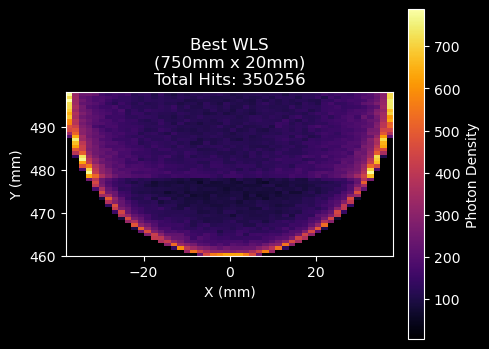

In [4]:
import uproot
import glob
import re
import matplotlib.pyplot as plt
import numpy as np
import gc

# --- 1. GLOBAL RESET ---
# Force the notebook back to standard white settings immediately
plt.style.use('default')

# --- CONFIGURATION ---
WLS = "KR"
REF = "Real"
TYPE = "Hit2"
TAU = "1.5"

# UPDATED PATTERN: Scans both Size and Thickness (wildcards *)
WLS_PATTERN = fr"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_{WLS}_Ref_{REF}_{TYPE}_Gap_0mm_Size_*mm_Thick_*mm_Tau_{TAU}ns.root"

REF_FILES = [
    {"label": "8-inch PMT (Gold Standard)", "file": fr"/scratch/alice/j/jss55/G4Data/1000Runs/8-inchPMT_Ref_{REF}_{TYPE}.root"},
    {"label": "3-inch PMT (Benchmark)",     "file": fr"/scratch/alice/j/jss55/G4Data/1000Runs/3-inchPMT_Ref_{REF}_{TYPE}.root"}
]
BINS = 50

# --- 2. FIND THE BEST WLS FILE ---
print(f"Scanning WLS files ({WLS_PATTERN}) to find the champion...")
wls_files = glob.glob(WLS_PATTERN)
best_wls = {"file": None, "count": -1, "label": "None"}

# Regex parsers for dimensions
re_size = re.compile(r"Size_(\d+)mm")
re_thick = re.compile(r"Thick_(\d+)mm")

for fname in wls_files:
    try:
        with uproot.open(fname) as f:
            if "DetPhotons" in f:
                count = f["DetPhotons"].num_entries
                
                # Check if this file has more photons than the current best
                if count > best_wls["count"]:
                    # Extract dimensions for the label
                    match_s = re_size.search(fname)
                    match_t = re_thick.search(fname)
                    
                    s = match_s.group(1) if match_s else "?"
                    t = match_t.group(1) if match_t else "?"
                    
                    best_wls = {
                        "file": fname, 
                        "count": count, 
                        "label": f"Best WLS\n({s}mm x {t}mm)"
                    }
    except: pass

if best_wls["file"]:
    print(f"-> WLS Winner: {best_wls['label']} with {best_wls['count']} photons.")
    print(f"-> File: {best_wls['file']}")
else:
    print("-> No valid WLS files found.")

# --- 3. BUILD PLOT LIST ---
datasets = []
for ref in REF_FILES:
    if len(glob.glob(ref["file"])) > 0:
        datasets.append(ref)
if best_wls["file"]:
    datasets.append(best_wls)

# --- 4. PLOT WITH MANUAL DARK STYLING ---
if not datasets:
    print("No files to plot.")
else:
    # Create figure with a specific black background color
    # Adjust width based on how many plots we actually found
    fig, axes = plt.subplots(1, len(datasets), figsize=(5 * len(datasets), 5))
    fig.patch.set_facecolor('black')  # Sets the outer border to black

    # Ensure 'axes' is iterable if only 1 plot
    if len(datasets) == 1: axes = [axes] 

    for i, ax in enumerate(axes):
        data_item = datasets[i]
        fname = data_item["file"]
        label = data_item["label"]
        
        # --- MANUAL AXIS STYLING ---
        ax.set_facecolor('black')               # Inner plot background
        ax.title.set_color('white')             # Title color
        ax.xaxis.label.set_color('white')       # X-label color
        ax.yaxis.label.set_color('white')       # Y-label color
        ax.tick_params(axis='x', colors='white')# X-ticks
        ax.tick_params(axis='y', colors='white')# Y-ticks
        for spine in ax.spines.values():
            spine.set_edgecolor('white')        # Border lines
        
        try:
            with uproot.open(fname) as f:
                if "DetPhotons" in f:
                    # Using library="np" for speed
                    data = f["DetPhotons"].arrays(["fX", "fY"], library="np")
                    count = len(data["fX"])
                    
                    if count > 0:
                        # cmin=1 makes empty bins transparent (showing black background)
                        h = ax.hist2d(data["fX"], data["fY"], bins=BINS, cmap='inferno', cmin=1)
                        
                        ax.set_title(f"{label}\nTotal Hits: {count}")
                        ax.set_xlabel("X (mm)")
                        ax.set_ylabel("Y (mm)")
                        ax.set_aspect('equal')
                        
                        # --- MANUAL COLORBAR STYLING ---
                        cbar = plt.colorbar(h[3], ax=ax, fraction=0.046, pad=0.04)
                        cbar.set_label("Photon Density", color='white')
                        cbar.ax.yaxis.set_tick_params(color='white') # Ticks
                        plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white') # Numbers
                        cbar.outline.set_edgecolor('white')

                    else:
                        ax.text(0.5, 0.5, "0 Detected", ha='center', color='white')
                        ax.set_title(f"{label} (Empty)")
                else:
                    ax.text(0.5, 0.5, "No Data", ha='center', color='white')
            
            gc.collect()

        except Exception as e:
            print(f"Error reading {label}: {e}")
            ax.text(0.5, 0.5, "Error", ha='center', color='red')

    plt.tight_layout()
    plt.show()

Scanning files matching: /scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_KR_Ref_Real_Hit2_Gap_0mm_Size_*mm_Thick_*mm_Tau_1.5ns.root
Found 140 files. Processing...

--- OPTIMIZATION RESULT ---
Global Maximum: 145166 photons
Optimal Config: Size 750mm x Thickness 20mm
-> Generating slices through this optimal point.



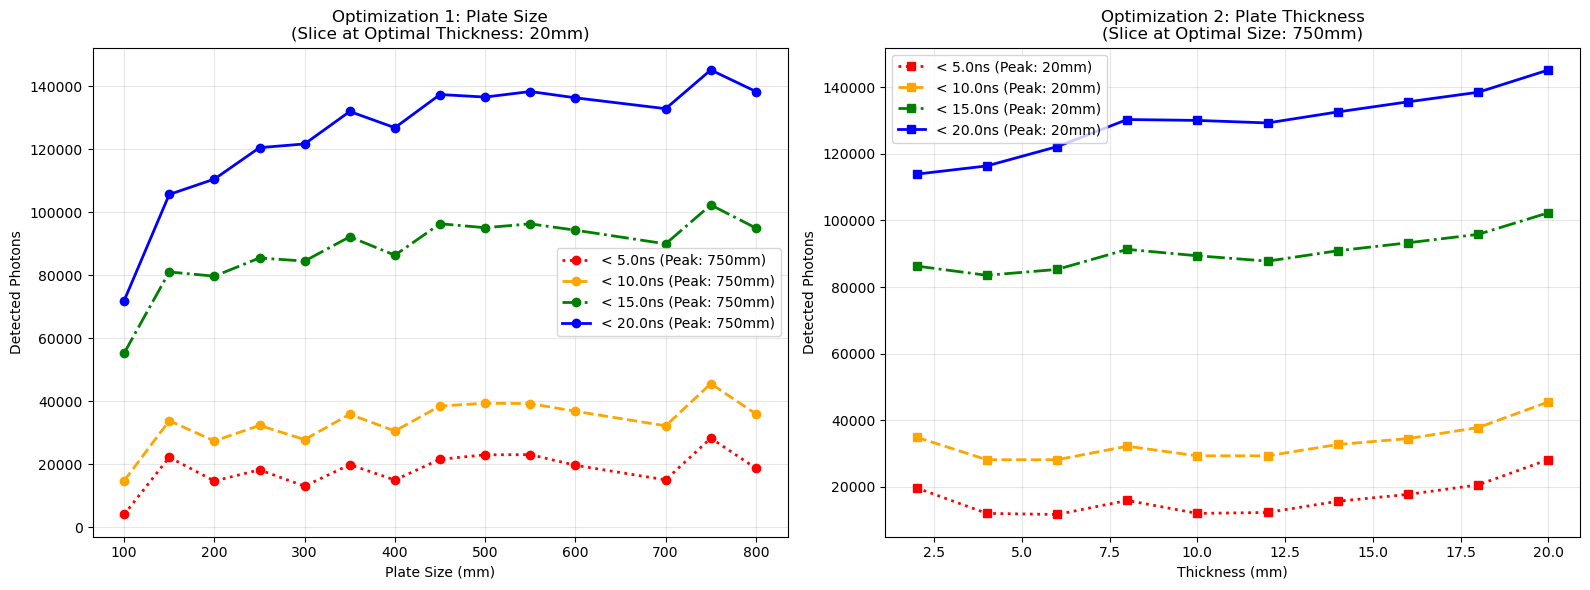

In [5]:
import uproot
import glob
import re
import matplotlib.pyplot as plt
import numpy as np

# --- CONFIGURATION ---
# 1. Timing Intervals to check (in nanoseconds)
TIME_CUTS = [5.0, 10.0, 15.0, 20.0]

WLS = "KR"
REF = "Real"
TYPE = "Hit2"   
TAU = "1.5"

# 2. File Pattern (Using wildcards for BOTH Size and Thickness)
# We calculate the optimal slice dynamically instead of hardcoding 9mm/450mm
FILE_PATTERN = fr"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_{WLS}_Ref_{REF}_{TYPE}_Gap_0mm_Size_*mm_Thick_*mm_Tau_{TAU}ns.root"

def parse_filename(fname):
    """Extracts Size and Thickness from filename."""
    s = re.search(r"Size_(\d+)mm", fname)
    t = re.search(r"Thick_(\d+)mm", fname)
    if s and t:
        return int(s.group(1)), int(t.group(1))
    return None, None

# --- 1. GLOBAL DATA LOAD ---
print(f"Scanning files matching: {FILE_PATTERN}")
files = glob.glob(FILE_PATTERN)

all_data = [] # Stores dicts: {'size': int, 'thick': int, 'counts': [c_5ns, c_10ns...]}

print(f"Found {len(files)} files. Processing...")

for fname in files:
    size, thick = parse_filename(fname)
    if size is None or thick is None: continue

    try:
        with uproot.open(fname) as f:
            if "DetPhotons" in f:
                # Load Time Array
                # Using library="np" for efficient array handling
                times = f["DetPhotons"]["fT"].array(library="np")
                
                # Calculate counts for each time cut
                # (Simple boolean masking is fast and robust)
                counts = [np.sum(times < t) for t in TIME_CUTS]
                
                all_data.append({
                    'size': size,
                    'thick': thick,
                    'counts': counts
                })
    except Exception as e:
        # print(f"Skipping {fname}: {e}")
        pass

if not all_data:
    print("No valid data found.")
    exit()

# --- 2. FIND OPTIMAL CONFIGURATION ---
# We define the "Best" configuration as the one with the highest count 
# at the most relaxed time cut (last element of TIME_CUTS)
best_entry = max(all_data, key=lambda x: x['counts'][-1])

OPT_SIZE = best_entry['size']
OPT_THICK = best_entry['thick']
max_photons = best_entry['counts'][-1]

print(f"\n--- OPTIMIZATION RESULT ---")
print(f"Global Maximum: {max_photons} photons")
print(f"Optimal Config: Size {OPT_SIZE}mm x Thickness {OPT_THICK}mm")
print(f"-> Generating slices through this optimal point.\n")

# --- 3. PREPARE SLICES ---

# SLICE A: Vary Size (Fixed Thickness = OPT_THICK)
# Filter data where thickness matches the optimum
slice_size_data = [d for d in all_data if d['thick'] == OPT_THICK]
slice_size_data.sort(key=lambda x: x['size']) # Sort by X-axis (Size)

x_size = [d['size'] for d in slice_size_data]
# Transpose counts to get lists per time-cut: [[5ns_data...], [10ns_data...]]
y_size = list(zip(*[d['counts'] for d in slice_size_data])) if slice_size_data else []


# SLICE B: Vary Thickness (Fixed Size = OPT_SIZE)
# Filter data where size matches the optimum
slice_thick_data = [d for d in all_data if d['size'] == OPT_SIZE]
slice_thick_data.sort(key=lambda x: x['thick']) # Sort by X-axis (Thickness)

x_thick = [d['thick'] for d in slice_thick_data]
y_thick = list(zip(*[d['counts'] for d in slice_thick_data])) if slice_thick_data else []


# --- 4. PLOT ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = ['red', 'orange', 'green', 'blue']
styles = [':', '--', '-.', '-']

# PLOT A: Varying Size
ax1 = axes[0]
if x_size:
    for i, cut in enumerate(TIME_CUTS):
        counts = y_size[i]
        # Label the peak of this specific curve
        max_y = max(counts)
        max_x = x_size[counts.index(max_y)]
        
        ax1.plot(x_size, counts, color=colors[i], linestyle=styles[i], marker='o', linewidth=2, 
                 label=f'< {cut}ns (Peak: {max_x}mm)')
    
    ax1.set_title(f"Optimization 1: Plate Size\n(Slice at Optimal Thickness: {OPT_THICK}mm)")
    ax1.set_xlabel("Plate Size (mm)")
    ax1.set_ylabel("Detected Photons")
    ax1.grid(True, alpha=0.3)
    ax1.legend()
else:
    ax1.text(0.5, 0.5, "No Data for Size Slice", ha='center')

# PLOT B: Varying Thickness
ax2 = axes[1]
if x_thick:
    for i, cut in enumerate(TIME_CUTS):
        counts = y_thick[i]
        # Label the peak of this specific curve
        max_y = max(counts)
        max_x = x_thick[counts.index(max_y)]
        
        ax2.plot(x_thick, counts, color=colors[i], linestyle=styles[i], marker='s', linewidth=2,
                 label=f'< {cut}ns (Peak: {max_x}mm)')

    ax2.set_title(f"Optimization 2: Plate Thickness\n(Slice at Optimal Size: {OPT_SIZE}mm)")
    ax2.set_xlabel("Thickness (mm)")
    ax2.set_ylabel("Detected Photons")
    ax2.grid(True, alpha=0.3)
    ax2.legend()
else:
    ax2.text(0.5, 0.5, "No Data for Thickness Slice", ha='center')

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os

# --- 1. Helper Function to Read Input .txt Files ---
def read_input_spectrum(filename, scale_factor=1.0):
    if not os.path.exists(filename):
        print(f"Warning: File not found -> {filename}")
        return np.array([]), np.array([])
    
    try:
        data = np.loadtxt(filename)
        energy_ev = data[:, 0]
        value = data[:, 1]
        wavelength_nm = 1239.84193 / energy_ev
        scaled_value = value * scale_factor
        sorted_indices = np.argsort(wavelength_nm)
        return wavelength_nm[sorted_indices], scaled_value[sorted_indices]
    except Exception as e:
        print(f"Error reading {filename}: {e}")
        return np.array([]), np.array([])

# --- 2. Peak Finder Helper ---
def find_peak_in_range(wavelength, value, min_wlen=300, max_wlen=550):
    """
    Finds the peak wavelength only within the visible range (300-550nm).
    This avoids picking up deep UV values (200nm) as the peak.
    """
    # Create a mask for the desired range
    mask = (wavelength >= min_wlen) & (wavelength <= max_wlen)
    if not np.any(mask): return 0 # Safety check
    
    # Apply mask
    w_masked = wavelength[mask]
    v_masked = value[mask]
    
    # Find max in this specific region
    peak_idx = np.argmax(v_masked)
    return w_masked[peak_idx]

# --- 3. Main Plotting Function ---
def compare_materials():
    # Create plot with twin axes
    fig, ax_abs = plt.subplots(figsize=(12, 7))
    ax_emm = ax_abs.twinx()

    print("Loading material files...")

    styles = {
        'EJ':      {'color': 'tab:blue',   'label': 'EJ-286'},
        'Kuraray': {'color': 'tab:orange', 'label': 'Kuraray (PMMA)'},
        'BC':      {'color': 'tab:green',  'label': 'BC-484'}
    }

    # --- A. KURARAY DATA ---
    wlen_k_abs, val_k_len = read_input_spectrum("../abslength_kuraray.txt") 
    wlen_k_emm, val_k_emm = read_input_spectrum("../emission_kuraray_active.txt")
    
    s = styles['Kuraray']
    if len(wlen_k_abs) > 0:
        val_k_coeff = np.divide(1.0, val_k_len, out=np.zeros_like(val_k_len), where=val_k_len!=0)
        # FIX: Find peak only > 300nm
        peak_nm = find_peak_in_range(wlen_k_abs, val_k_coeff)
        ax_abs.plot(wlen_k_abs, val_k_coeff, color=s['color'], linestyle='-', linewidth=2, label=f"{s['label']} Abs (Peak: {peak_nm:.0f} nm)")

    if len(wlen_k_emm) > 0:
        val_k_emm_norm = val_k_emm / np.max(val_k_emm)
        peak_nm = find_peak_in_range(wlen_k_emm, val_k_emm_norm)
        ax_emm.plot(wlen_k_emm, val_k_emm_norm, color=s['color'], linestyle='--', linewidth=2, label=f"{s['label']} Emm (Peak: {peak_nm:.0f} nm)")
        ax_emm.fill_between(wlen_k_emm, val_k_emm_norm, color=s['color'], alpha=0.1)

    # # --- B. EJ DATA ---
    # wlen_ej_abs, val_ej_len = read_input_spectrum("../abslength_EJ.txt") 
    # wlen_ej_emm, val_ej_emm = read_input_spectrum("../emission_EJ.txt")

    # s = styles['EJ']
    # if len(wlen_ej_abs) > 0:
    #     val_ej_coeff = np.divide(1.0, val_ej_len, out=np.zeros_like(val_ej_len), where=val_ej_len!=0)
    #     peak_nm = find_peak_in_range(wlen_ej_abs, val_ej_coeff)
    #     ax_abs.plot(wlen_ej_abs, val_ej_coeff, color=s['color'], linestyle='-', linewidth=2, label=f"{s['label']} Abs (Peak: {peak_nm:.0f} nm)")

    # if len(wlen_ej_emm) > 0:
    #     val_ej_emm_norm = val_ej_emm / np.max(val_ej_emm)
    #     peak_nm = find_peak_in_range(wlen_ej_emm, val_ej_emm_norm)
    #     ax_emm.plot(wlen_ej_emm, val_ej_emm_norm, color=s['color'], linestyle='--', linewidth=2, label=f"{s['label']} Emm (Peak: {peak_nm:.0f} nm)")
    #     ax_emm.fill_between(wlen_ej_emm, val_ej_emm_norm, color=s['color'], alpha=0.1)

    # --- C. BC DATA ---
    wlen_bc_abs, val_bc_len = read_input_spectrum("../abslength_BC.txt") 
    wlen_bc_emm, val_bc_emm = read_input_spectrum("../emission_BC.txt")

    s = styles['BC']
    if len(wlen_bc_abs) > 0:
        val_bc_coeff = np.divide(1.0, val_bc_len, out=np.zeros_like(val_bc_len), where=val_bc_len!=0)
        peak_nm = find_peak_in_range(wlen_bc_abs, val_bc_coeff)
        ax_abs.plot(wlen_bc_abs, val_bc_coeff, color=s['color'], linestyle='-', linewidth=2, label=f"{s['label']} Abs (Peak: {peak_nm:.0f} nm)")

    if len(wlen_bc_emm) > 0:
        val_bc_emm_norm = val_bc_emm / np.max(val_bc_emm)
        peak_nm = find_peak_in_range(wlen_bc_emm, val_bc_emm_norm)
        ax_emm.plot(wlen_bc_emm, val_bc_emm_norm, color=s['color'], linestyle='--', linewidth=2, label=f"{s['label']} Emm (Peak: {peak_nm:.0f} nm)")
        ax_emm.fill_between(wlen_bc_emm, val_bc_emm_norm, color=s['color'], alpha=0.1)

    # --- FORMATTING ---
    ax_abs.set_title("Material Comparison: Color Coded by Type", fontsize=14)
    ax_abs.set_xlabel("Wavelength (nm)", fontsize=12)
    ax_abs.set_xlim(300, 550)
    ax_abs.grid(True, alpha=0.3)
    
    ax_abs.set_ylabel("Abs Coefficient (1/mm) [Solid Lines]", color='black', fontsize=12)
    ax_emm.set_ylabel("Normalized Emission [Dashed Lines]", color='black', fontsize=12)
    ax_emm.set_ylim(0, 1.1)

    # Organize Legend
    lines1, labels1 = ax_abs.get_legend_handles_labels()
    lines2, labels2 = ax_emm.get_legend_handles_labels()
    
    if lines1 or lines2:
        ax_abs.legend(lines1 + lines2, labels1 + labels2, loc='upper right', ncol=1, fontsize=10)

    plt.tight_layout()
    plt.show()

# --- Run ---
compare_materials()

Found 1 files. Analyzing...


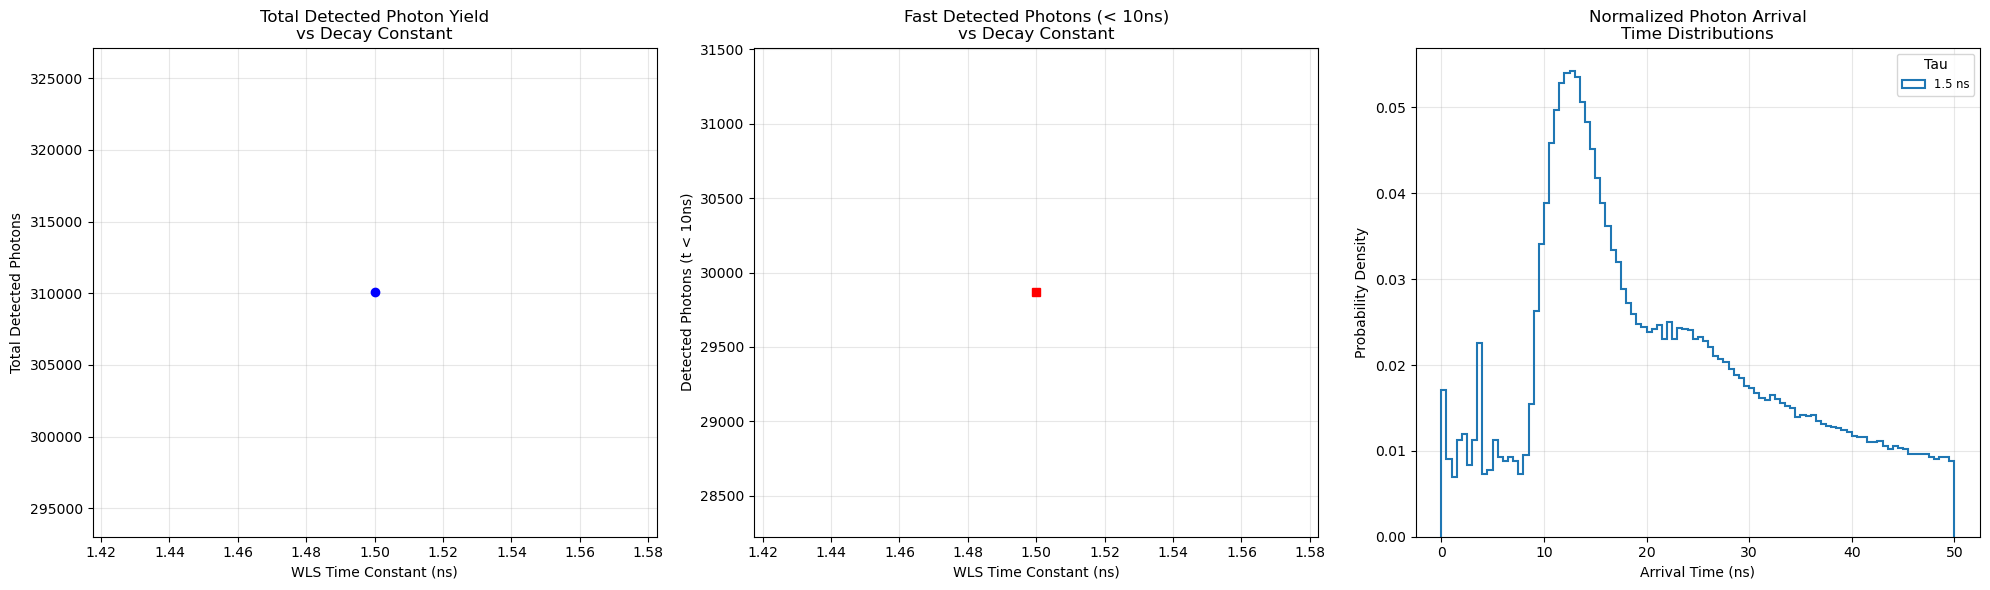

In [7]:
import uproot
import matplotlib.pyplot as plt
import numpy as np
import glob
import re

WLS = "KR"
REF = "Real"
TYPE = "Hit2" # Change to "Hit2" if your new files use that naming convention
# Adjust path if files are not in a 'data' subfolder
file_pattern = fr"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_{WLS}_Ref_{REF}_{TYPE}_Gap_0mm_Size_350mm_Thick_10mm_Tau_*ns.root"

def get_tau(filename):
    """Extracts tau value (e.g., 1.5) from filename."""
    match = re.search(r'Tau_([\d.]+)ns', filename)
    return float(match.group(1)) if match else 0

files = glob.glob(file_pattern)
files.sort(key=get_tau) # Sort files by Tau value (1.0, 1.5, 2.0...)

tau_values = []
total_counts = []
cut_counts = [] # Storage for < 10ns counts
time_distributions = []

print(f"Found {len(files)} files. Analyzing...")

for filename in files:
    tau = get_tau(filename)
    
    with uproot.open(filename) as file:
        if "DetPhotons;1" in file:
            # Get arrival times (fT)
            times = file["DetPhotons"]["fT"].array(library="np")
            
            tau_values.append(tau)
            
            # 1. Total Count
            total_counts.append(len(times)) 
            
            # 2. Count < 10ns (Time Cut)
            count_10ns = np.sum(times < 10.0)
            cut_counts.append(count_10ns)
            
            time_distributions.append((tau, times))

# --- PLOTTING ---
# Changed to 1 row, 3 columns to accommodate the new plot
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

# Plot 1: Total Yield vs Tau
ax1.plot(tau_values, total_counts, 'o-', color='blue', linewidth=2)
ax1.set_title("Total Detected Photon Yield\nvs Decay Constant")
ax1.set_xlabel("WLS Time Constant (ns)")
ax1.set_ylabel("Total Detected Photons")
ax1.grid(True, alpha=0.3)

# Plot 2: Yield < 10ns vs Tau (NEW)
ax2.plot(tau_values, cut_counts, 's-', color='red', linewidth=2)
ax2.set_title("Fast Detected Photons (< 10ns)\nvs Decay Constant")
ax2.set_xlabel("WLS Time Constant (ns)")
ax2.set_ylabel("Detected Photons (t < 10ns)")
ax2.grid(True, alpha=0.3)

# Plot 3: Pulse Shape Comparison (Overlaid Histograms)
for tau, times in time_distributions:
    # Plotting step histograms for arrival times
    ax3.hist(times, bins=100, range=(0, 50), histtype='step', 
             linewidth=1.5, label=f"{tau} ns", density=True)

ax3.set_title("Normalized Photon Arrival\nTime Distributions")
ax3.set_xlabel("Arrival Time (ns)")
ax3.set_ylabel("Probability Density")
ax3.legend(title="Tau", fontsize='small')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os

def load_data(filename):
    """
    Tries to load data from current dir, data/ dir, or parent dir.
    Returns (wavelength, value) arrays or (None, None).
    """
    # Potential paths to check
    paths = [
        filename,
        os.path.join("data", filename),
        os.path.join("..", filename)
    ]
    
    found_path = None
    for p in paths:
        if os.path.exists(p):
            found_path = p
            break
            
    if not found_path:
        print(f"Warning: {filename} not found in search paths.")
        return None, None
    
    try:
        data = np.loadtxt(found_path)
        # Check if 2 columns
        if data.shape[1] < 2:
            return None, None
            
        # Detect if input is likely eV (small numbers < 100) or nm (large numbers > 100)
        if np.mean(data[:, 0]) < 100:
            wlen = 1239.84193 / data[:, 0]
        else:
            wlen = data[:, 0]
            
        val = data[:, 1]
        
        # Sort by wavelength for clean plotting
        idx = np.argsort(wlen)
        return wlen[idx], val[idx]
    except Exception as e:
        print(f"Error reading {found_path}: {e}")
        return None, None

# --- 1. DEFINITIONS ---

# PMT Quantum Efficiency Data
qe_data = [
    (650, 0.001), (625, 0.005), (600, 0.014), (575, 0.030),
    (550, 0.052), (525, 0.081), (500, 0.119), (475, 0.156),
    (450, 0.200), (425, 0.219), (400, 0.232), (375, 0.227),
    (350, 0.216), (325, 0.188), (300, 0.086), (275, 0.000)
]
qe_data.sort(key=lambda x: x[0])
w_qe = np.array([x[0] for x in qe_data])
v_qe = np.array([x[1] for x in qe_data])

# Normalize QE for relative shape comparison
v_qe_norm = v_qe / np.max(v_qe)

# Cherenkov Spectrum (1/lambda^2)
w_cherenkov = np.linspace(250, 700, 500)
v_cherenkov = 1.0 / (w_cherenkov**2)
# Normalize to 1.0
v_cherenkov = v_cherenkov / np.max(v_cherenkov) 

# Load Kuraray Data
w_abs_k, v_abs_k = load_data("abslength_kuraray.txt")
w_emm_k, v_emm_k = load_data("emission_kuraray_active.txt")

# --- 2. PLOTTING ---
fig, ax1 = plt.subplots(figsize=(10, 7))

lines = []

# 1. Absorption (Normalized)
if w_abs_k is not None:
    valid_mask = v_abs_k > 0
    # Calculate Abs Coeff (1/mm) then Normalize
    abs_coeff = 1.0 / (v_abs_k[valid_mask] * 10)
    abs_norm = abs_coeff / np.max(abs_coeff) # Normalization step
    w_abs_plot = w_abs_k[valid_mask]
    
    l1, = ax1.plot(w_abs_plot, abs_norm, color='navy', linewidth=2.5, label='WLS Abs. Spectrum (Norm)')
    lines.append(l1)
else:
    print("Kuraray Absorption data not found, skipping plot.")

# 2. Emission (Normalized)
if w_emm_k is not None:
    norm_emm = v_emm_k / np.max(v_emm_k)
    l2, = ax1.plot(w_emm_k, norm_emm, color='limegreen', linewidth=2.5, label='WLS Emission (Norm)')
    # Add fill for visibility
    ax1.fill_between(w_emm_k, norm_emm, color='limegreen', alpha=0.15)
    lines.append(l2)

# 3. PMT QE (Normalized)
# Plotting normalized version to compare spectral shape overlap
l3, = ax1.plot(w_qe, v_qe_norm, color='red', linestyle='--', linewidth=2, label='PMT QE Shape (Norm)')
lines.append(l3)

# 4. Cherenkov (Normalized)
l4, = ax1.plot(w_cherenkov, v_cherenkov, color='purple', linestyle=':', linewidth=2, alpha=0.8, label=r'Cherenkov Spectrum ($1/\lambda^2$)')
lines.append(l4)

# Formatting
ax1.set_xlabel("Wavelength (nm)", fontsize=12)
ax1.set_ylabel("Normalized Intensity / Probability (a.u.)", fontsize=12)
ax1.set_ylim(0, 1.1)
ax1.set_xlim(300, 650)
ax1.grid(True, alpha=0.3)

# Legend
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right', framealpha=0.9, shadow=True, fontsize=10)

plt.title("Relative Spectral Comparison: WLS Properties, Cherenkov & PMT")
plt.tight_layout()
plt.show()

Label                          | Avg/Event       | Total     
-----------------------------------------------------------------
3-inch PMT Hits                | 28.517          | 28517     
3-inch PMT Dets                | 28.517          | 28517     
WLS Hits                       | 32.207          | 32207     
WLS Dets                       | 32.207          | 32207     
5-inch PMT Hits                | 93.821          | 93821     
5-inch PMT Dets                | 93.821          | 93821     

               COMPARATIVE IMPROVEMENT FACTORS               
 Comparison                          | Factor (x better)   
------------------------------------------------------------
 WLS Hit vs 3-inch Hit               | 1.13x
 WLS Det vs 3-inch Det               | 1.13x
------------------------------------------------------------
 5-inch Hit vs 3-inch Hit            | 3.29x
 5-inch Det vs 3-inch Det            | 3.29x
------------------------------------------------------------
 8-inch Hit vs

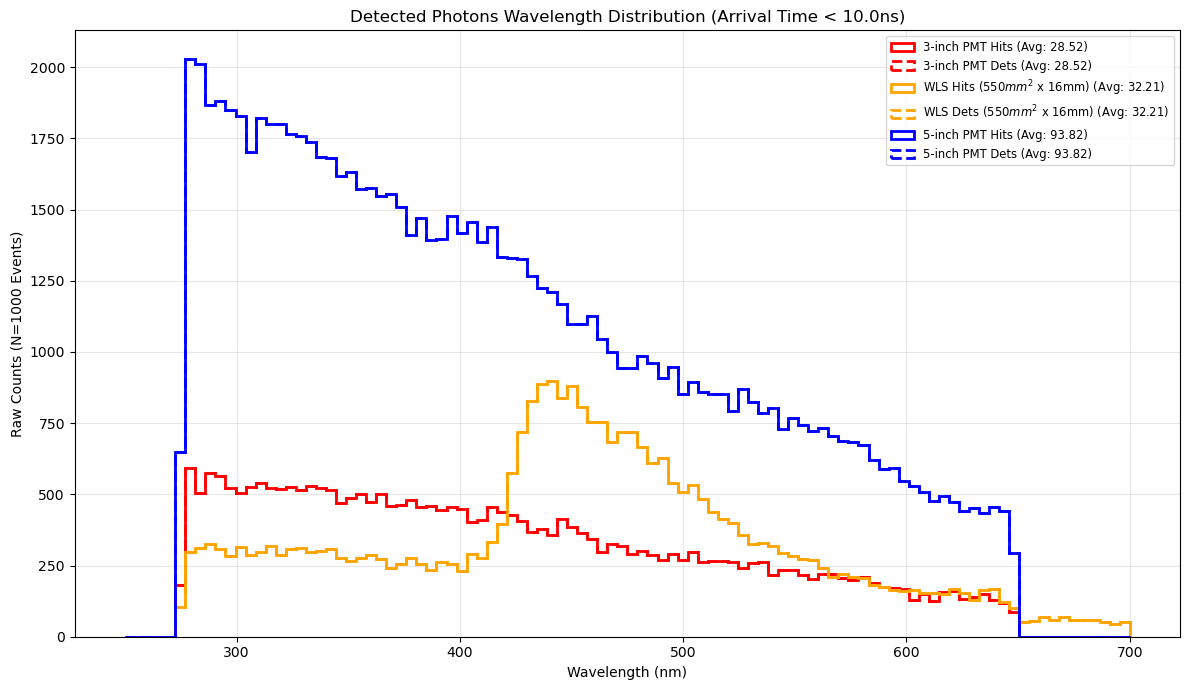

In [8]:
import uproot
import matplotlib.pyplot as plt
import numpy as np
import os
import re  # Added for extracting dimensions from filename

# --- CONFIGURATION ---
N_EVT = 1000      # Total number of primary events generated
USE_TIME_CUT = True # Toggle to True to filter by TIME_LIMIT, False to include all
TIME_LIMIT = 10.0 # Nanoseconds (Time cut)

WLS = "KR"
REF = "Real"
TYPE1 = "Hit2" # Standard Detection
TYPE2 = "Hit2" # Explicit Optical Process
TAU = "1.5"

# Setup file paths - Looking for both Hit and Det
file_configs = [
    (f"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/3-inchPMT_Ref_{REF}_{TYPE2}.root", "3-inch PMT Hits"),
    (f"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/3-inchPMT_Ref_{REF}_{TYPE1}.root", "3-inch PMT Dets"),
    
    (f"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_{WLS}_Ref_{REF}_{TYPE2}_Gap_0mm_Size_550mm_Thick_16mm_Tau_{TAU}ns.root", "WLS Hits"),
    (f"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/WLS_{WLS}_Ref_{REF}_{TYPE1}_Gap_0mm_Size_550mm_Thick_16mm_Tau_{TAU}ns.root", "WLS Dets"),
    
    (f"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/5-inchPMT_Ref_{REF}_{TYPE2}.root", "5-inch PMT Hits"),
    (f"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/5-inchPMT_Ref_{REF}_{TYPE1}.root", "5-inch PMT Dets"),

    (f"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/8-inchPMT_Ref_{REF}_{TYPE2}.root", "8-inch PMT Hits"),
    (f"/scratch/alice/j/jss55/G4Data/NewMuonGen_RealRef_PolishedWLSPMTBound_ShellPMT/8-inchPMT_Ref_{REF}_{TYPE1}.root", "8-inch PMT Dets"),
]

# --- UPDATED COLOR MAP ---
color_map = {
    "3-inch PMT": "red", 
    "5-inch PMT": "blue",
    "8-inch PMT": "green", 
    "WLS": "orange"
}

integrals = {}

# Create figure and primary axis
fig, ax1 = plt.subplots(figsize=(12, 7))
files_found = 0

print(f"{'Label':<30} | {'Avg/Event':<15} | {'Total':<10}")
print("-" * 65)

for fname, label in file_configs:
    # 1. Resolve File Path
    if os.path.exists(fname):
        path = fname
    elif os.path.exists(os.path.join("..", fname)):
        path = os.path.join("..", fname)
    else:
        basename = os.path.basename(fname)
        if os.path.exists(basename):
            path = basename
        else:
            continue # File not found

    files_found += 1
    
    try:
        with uproot.open(path) as root_file:
            if "DetPhotons" in root_file:
                tree = root_file["DetPhotons"]
                # Load branches
                branches = tree.arrays(["fwlen", "fT"], library="np")
                wlen = branches["fwlen"]
                time = branches["fT"]
                
                # Apply Time Cut
                if USE_TIME_CUT:
                    mask = (time <= TIME_LIMIT)
                    filtered_wlen = wlen[mask]
                else:
                    filtered_wlen = wlen
                
                # Calculate Stats
                total_count = len(filtered_wlen)
                avg_count = total_count / N_EVT
                integrals[label] = total_count
                
                print(f"{label:<30} | {avg_count:<15.3f} | {total_count:<10}")
                
                # Determine Color
                c = "black"
                width = 2
                for key, val in color_map.items():
                    if key in label:
                        c = val
                        break

                # --- NEW: Extract Dimensions for WLS Labels ---
                plot_label = label
                if "WLS" in label:
                    # Regex to find Size_XXXmm and Thick_YYmm
                    # Looks for: Size_(digits followed by letters)_ ... Thick_(digits followed by letters)
                    match = re.search(r"Size_(\d+mm)_Thick_(\d+mm)", path)
                    if match:
                        size_dim = match.group(1)
                        thick_dim = match.group(2)
                        
                        # Add ^2 to size as requested
                        size_dim = size_dim.replace("mm", r"$mm^2$")
                        
                        plot_label = f"{label} ({size_dim} x {thick_dim})"
                
                # Append Stats to Label
                final_label = f"{plot_label} (Avg: {avg_count:.2f})"

                # Plot Histogram
                linestyle = '--' if "Det" in label else '-'
                
                ax1.hist(filtered_wlen, bins=100, range=(250, 700), 
                         histtype='step', 
                         linestyle=linestyle,
                         linewidth=width,
                         color=c, 
                         label=final_label)
                          
    except Exception as e:
        print(f"Error reading {fname}: {e}")

# --- COMPARATIVE ANALYSIS ---
print(f"\n{'='*60}")
print(f" {'COMPARATIVE IMPROVEMENT FACTORS':^60}")
print(f"{'='*60}")
print(f" {'Comparison':<35} | {'Factor (x better)':<20}")
print(f"{'-'*60}")

def print_ratio(num_label, den_label, desc):
    num = integrals.get(num_label)
    den = integrals.get(den_label)
    if num is not None and den is not None:
        if den == 0:
            print(f" {desc:<35} | {'Infinite (Ref=0)':<20}")
        else:
            ratio = num / den
            print(f" {desc:<35} | {ratio:<.2f}x")
    else:
        # Check if keys exist at all to warn user
        if num is None and den is None:
             pass # Likely just files missing
        else:
             print(f" {desc:<35} | {'Data Missing':<20}")

print_ratio("WLS Hits", "3-inch PMT Hits", "WLS Hit vs 3-inch Hit")
print_ratio("WLS Dets", "3-inch PMT Dets", "WLS Det vs 3-inch Det")
print(f"{'-'*60}")
print_ratio("5-inch PMT Hits", "3-inch PMT Hits", "5-inch Hit vs 3-inch Hit")
print_ratio("5-inch PMT Dets", "3-inch PMT Dets", "5-inch Det vs 3-inch Det")
print(f"{'-'*60}")
print_ratio("8-inch PMT Hits", "3-inch PMT Hits", "8-inch Hit vs 3-inch Hit")
print_ratio("8-inch PMT Dets", "3-inch PMT Dets", "8-inch Det vs 3-inch Det")
print(f"{'='*60}\n")

if files_found == 0:
    print("\nERROR: No files were found. Check your directory and filenames.")
else:
    time_info = f"(Arrival Time < {TIME_LIMIT}ns)" if USE_TIME_CUT else "(No Time Cut)"
    ax1.set_title(f"Detected Photons Wavelength Distribution {time_info}")
    ax1.set_xlabel("Wavelength (nm)")
    ax1.set_ylabel(f"Raw Counts (N={N_EVT} Events)")
    ax1.legend(fontsize='small', loc='upper right')
    ax1.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
import uproot
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import glob
import os

def analyze_sweet_spot(file_list, time_steps=np.arange(5, 55, 5)):
    results = []
    print(f"Analyzing {len(file_list)} files...")

    # Regex to extract both Size and Thickness
    # matches: ..._Size_200mm_Thick_9mm...
    pattern = re.compile(r"_Size_(\d+)mm_Thick_(\d+)mm")

    for file_path in file_list:
        match = pattern.search(file_path)
        if match:
            diameter = int(match.group(1))
            thickness = int(match.group(2))
        else:
            print(f"Warning: Could not parse dimensions from {file_path}")
            continue
            
        try:
            with uproot.open(file_path) as f:
                # Load necessary data into Pandas DataFrames
                det_df = f["DetPhotons"].arrays(library="pd")
                abs_df = f["AbsPhotons"].arrays(library="pd")
                emm_df = f["EmmPhotons"].arrays(library="pd")
                esc_df = f["EscapedPhotons"].arrays(library="pd")

                # 1. Fundamental Counts
                # Total Cherenkov photons absorbed in WLS (Volume 1)
                total_absorbed = len(abs_df[abs_df["fPreVolumeID"] == 1])
                # Total WLS photons re-emitted
                total_emitted = len(emm_df)
                # Total WLS photons that escaped through the surface
                total_escaped = len(esc_df)
                # Total photons hitting the PMT
                total_detected = len(det_df)

                # 2. Geometric Efficiencies
                trapping_eff = (1 - (total_escaped / total_emitted)) if total_emitted > 0 else 0
                collection_eff = total_detected / total_emitted if total_emitted > 0 else 0

                # 3. Timing Sweep
                for t_cut in time_steps:
                    on_time_hits = len(det_df[det_df["fT"] <= t_cut])
                    
                    abs_eff = on_time_hits / total_absorbed if total_absorbed > 0 else 0
                    timing_eff = on_time_hits / total_detected if total_detected > 0 else 0

                    results.append({
                        'Diameter': diameter,
                        'Thickness': thickness,
                        'TimeCut': t_cut,
                        'AbsEff': abs_eff,
                        'TimingEff': timing_eff,
                        'TrappingEff': trapping_eff,
                        'CollectionEff': collection_eff
                    })
        except Exception as e:
            # print(f"Error reading file {file_path}: {e}")
            pass

    return pd.DataFrame(results)

# --- CONFIGURATION ---
WLS = "KR"
REF = "1"
TYPE = "Hit"
TAU = "1.5"
DATA_DIR = "/scratch/alice/j/jss55/G4Data/1000Runs/" # Leave empty if files are in current directory

# 1. GENERATE FILE LIST AUTOMATICALLY
# This pattern matches ANY Size and ANY Thickness
search_pattern = f"{DATA_DIR}WLS_{WLS}_Ref_{REF}_{TYPE}_Size_*mm_Thick_*mm_Tau_{TAU}ns.root"
existing_files = glob.glob(search_pattern)

if not existing_files:
    print(f"Error: No files found matching pattern: {search_pattern}")
else:
    # 2. RUN ANALYSIS
    df = analyze_sweet_spot(existing_files)

    if not df.empty:
        # 3. FIND OPTIMAL THICKNESS (Global Maximum Efficiency)
        # We look for the row with the highest AbsEff at the largest time cut
        best_row = df.loc[df['AbsEff'].idxmax()]
        best_thick = int(best_row['Thickness'])
        best_size = int(best_row['Diameter'])
        
        print(f"\n--- OPTIMIZATION RESULTS ---")
        print(f"Global Best Efficiency: {best_row['AbsEff']*100:.2f}%")
        print(f"Achieved at: Size {best_size}mm x Thickness {best_thick}mm")
        print(f"-> Plotting Size Sweep for Optimal Thickness ({best_thick}mm)")

        # 4. PLOT: Efficiency vs Size (at Best Thickness)
        plt.figure(figsize=(10, 6))
        
        # Filter for the "Best Thickness" found above
        subset_thick = df[df['Thickness'] == best_thick]
        
        plot_times = [10, 20, 30, 50]
        for t in plot_times:
            sub_time = subset_thick[subset_thick['TimeCut'] == t]
            sub_time = sub_time.sort_values(by="Diameter") 
            if not sub_time.empty:
                plt.plot(sub_time['Diameter'], sub_time['AbsEff']*100, marker='o', label=f'Time < {t}ns')

        plt.title(f"Absolute Efficiency vs. Plate Size (at Best Thickness: {best_thick}mm)")
        plt.xlabel("Plate Diameter (mm)")
        plt.ylabel("Absolute Efficiency (%)")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    else:
        print("Files found, but no valid data extracted.")